# Finalna analiza projektu – wydarzenia migracyjne a mowa nienawiści

**Jeden notebook, który spina cały projekt:** co i jak zrobiliśmy, na jakich danych i jakimi modelami, jak dobre są etykiety
(gold standard), co wyszło dla każdej hipotezy (H1–H4) i co mówią treść i autorzy hejtu.

**Pytanie badawcze:** czy istotne wydarzenia społeczne, polityczne i medialne związane z migrantami są powiązane ze zmianami
poziomu mowy nienawiści (wobec migrantów) w polskojęzycznych mediach społecznościowych?

| część | co jest w środku | skąd |
|---|---|---|
| **1. Projekt w skrócie** | hipotezy, dane, wydarzenia, pipeline, modele | README, `docs/` |
| **2. Jakość etykiet** | gold standard: zgodność anotatorów, F1 / precision / recall, ROC, macierze pomyłek | `3_gold_standard/08–10` |
| **3. Dane do testów** | komórki wydarzenie × platforma, wolumen | jak w analizie Oli |
| **4. Efekty wydarzeń** | zmiana przed → po w każdej komórce | analiza Oli + regresja z klastrami |
| **5–8. H1–H4** | testy z README + metaanaliza, wykresy | nowe (H3 nie było w analizie Oli) |
| **9. Treść i autorzy hejtu** | słowa, kogo obrażano, koncentracja autorów, polubienia | `cross_platform_hate_analysis.ipynb` (Ola) |
| **10–11. Podsumowanie i wnioski** | werdykty hipotez, odpowiedź na pytanie badawcze, ograniczenia | – |

Ustalenia jak w analizie międzyplatformowej zespołu (`4_analizy_llm_hate_migrant/cross_platform_hate_analysis.ipynb`, Ola;
`docs/ANALIZA_MIEDZYPLATFORMOWA.md`): **7 wydarzeń**, okno **−7…+14 dni** (przed = −7…−1, po = 0…+14), te same etykiety LLM
i typy wydarzeń, YouTube / Śmierć żołnierza wykluczone (cały okres „przed” to jeden film). Jednostka analizy:
**komórka wydarzenie × platforma**. Ten notebook dokłada testy z README, H3, drugi tor etykiet (**HerBERT**) i gold standard.

| miara | co mierzy | źródło etykiety | rola |
|---|---|---|---|
| `hate_migrant` | % komentarzy z hejtem wobec migrantów | LLM (Ollama) + słownik obelg | **główna** – odpowiada na pytanie badawcze |
| `hate (HerBERT)` | % komentarzy z hejtem (ogólnym) | HerBERT + słownik obelg | niezależne sprawdzenie na najlepszym klasyfikatorze |

**Na jakich komentarzach:** tylko na komentarzach **o migracji**, czyli tych, które są w `labeled/` (wybrane przez filtr
słownikowy + LLM albo przez słownik obelg; na Wykopie: `topic/` i LLM „o migracji” lub obelga ze słownika). Komentarzy spoza
`labeled/` **nie analizujemy** (nie są traktowane jako 0) – obie miary liczymy na tym samym zbiorze komentarzy.

> **Bluesky:** etykiety LLM są dla wszystkich 7 wydarzeń, ale 4 wydarzenia z 2024 r. (Pakt, Śmierć żołnierza, Bójka, Strategia)
> mają w oknie tylko kilka–kilkanaście komentarzy w temacie i < 30 komentarzy przed wydarzeniem, więc są pomijane
> (`MIN_N_PERIOD = 30`). Na Bluesky zostają 3 komórki – to ograniczenie danych, nie brak etykiet.

In [1]:
# ── KONFIGURACJA ──────────────────────────────────────────────────────────────
PLATFORMS = ["wykop", "youtube", "bluesky"]
# typ i zasięg – jak w analizie zespołu (cross_platform_hate_analysis.ipynb, EVENT_META)
EVENT_META = {
    "Pakt_Azyl_PE":               ("polityczne",       "zagraniczne"),
    "Smierc_Zolnierza":           ("kryminalne",       "krajowe"),
    "Bojka_Srem":                 ("kryminalne",       "krajowe"),
    "Strategia_Migracyjna":       ("polityczne",       "krajowe"),
    "Dezinformacja_Krakow":       ("dezinformacja",    "krajowe"),
    "Ceuta_Masowe_Przekroczenie": ("kryzys graniczny", "zagraniczne"),
    "Atak_Kamienna_Gora":         ("kryminalne",       "krajowe"),
}
EXCLUDE = {("youtube", "Smierc_Zolnierza")}
WINDOW = (-7, 14)
POST_FROM_DAY = 0
H3_WINDOWS = {"dni 0–3": (0, 3), "dni 4–7": (4, 7), "dni 8–14": (8, 14)}   # vs baseline −7…−1
MIN_N_PERIOD = 30          # min. komentarzy w mianowniku przed i po (jak u zespołu)
MIN_DAILY_N = 10           # min. komentarzy w mianowniku dnia
ALPHA = 0.05
SEED = 42
MEASURES = {   # nazwa -> (licznik, mianownik: None = wszystkie komentarze)
    "hate_migrant": ("hate_migrant", None),
    "hate (HerBERT)": ("hate_herbert", "herbert_ok"),
}
MAIN = "hate_migrant"
MEASURE_NAMES = {
    "hate_migrant": "hejt wobec migrantów (LLM)",
    "hate (HerBERT)": "hejt (HerBERT)",
}

In [2]:
import json, sys, warnings
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from IPython.display import display
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import confint_proportions_2indep

warnings.filterwarnings("ignore", category=RuntimeWarning)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "events.json").exists())
OUT = ROOT / "reports" / "wyniki_koncowe"
OUT.mkdir(parents=True, exist_ok=True)
EVENTS = json.loads((ROOT / "events.json").read_text(encoding="utf-8"))
BEST = json.loads((ROOT / "reports" / "gold_model_eval" / "best_model.json").read_text(encoding="utf-8"))

INK, INK2, MUTED = "#1a2233", "#52514e", "#8a8984"
PLAT_COLORS = {"wykop": "#2a78d6", "youtube": "#eb6834", "bluesky": "#1baf7a"}
TYPE_ORDER = ["kryminalne", "polityczne", "dezinformacja", "kryzys graniczny"]
TYPE_COLORS = dict(zip(TYPE_ORDER, ["#c2410c", "#7c3aed", "#0f766e", "#b45309"]))
MEAS_COLORS = {"hate_migrant": "#c2410c", "hate (HerBERT)": "#2a78d6"}
plt.rcParams.update({
    "figure.figsize": (12, 4.5), "figure.dpi": 100, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "legend.frameon": False,
})
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 120)


def savefig(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=150, bbox_inches="tight")


def fmt_p(t, digits=3):
    t = t.copy()
    for c in t.columns:
        if str(c) == "p" or str(c).startswith("p "):
            t[c] = t[c].map(lambda v: "" if pd.isna(v) else f"{v:.3g}")
    return t.round(digits)

## 1. Projekt w skrócie

### Hipotezy (README)

| | hipoteza | test (README) |
|---|---|---|
| **H1** | wydarzenia związane z migrantami zmieniają poziom mowy nienawiści | Wilcoxon (przed vs po, parami) + wielkość efektu; dodatkowo metaanaliza efektów losowych |
| **H2** | siła i kierunek zmiany zależą od rodzaju wydarzenia | Kruskal–Wallis → Dunn + Holm |
| **H3** | zmiana jest największa tuż po wydarzeniu i potem słabnie | Friedman (okna 0–3, 4–7, 8–14) → Wilcoxon + Holm, każde okno vs baseline |
| **H4** | zależność różni się między YouTube, Wykopem i Bluesky | Kruskal–Wallis → Dunn + Holm |

### Dane

| | Wykop | YouTube | Bluesky |
|---|---|---|---|
| zbieranie | wpisy i komentarze ±28 dni, wyszukiwanie słowami o migracji | filmy z okna wokół wydarzenia, komentarze do 4 dni od publikacji | wpisy i komentarze ±28 dni, słowa o migracji |
| skrypt | `scripts/wykop.py` | `scripts/youtube.py` | `scripts/bluesky.py` |

Komentarze są zanonimizowane (pseudonimy zamiast identyfikatorów) i wersjonowane w DVC. Dane zebraliśmy wokół
**15 wydarzeń** (2022–2026); analiza główna obejmuje **7**, dla których zespół przygotował etykiety LLM.

### Dwa tory etykiet hejtu

| | **LLM** (zespół) | **klasyfikatory** (HerBERT i inne) |
|---|---|---|
| co oznacza | czy komentarz dotyczy migracji, czy jest hejtem, czy jest **hejtem wobec migrantów** | czy komentarz jest **hejtem** (ogólnie) |
| jak | lokalny LLM przez Ollamę (`scripts/topic_sample.py`, domyślnie `qwen2.5:7b`), prompt z codebookiem (`docs/CODEBOOK.md`); na Wykopie dodatkowo słownik obelg | najpierw słownik obelg (`src/lexicon/slurs.py`), potem model dla pozostałych komentarzy (p ≥ 0,5) |
| na czym | komentarze wstępnie wybrane jako dotyczące migracji (`labeled/`) | komentarze z filtra tematycznego zespołu (`scripts/topic_filter.py`) |
| modele | 1 LLM | **HerBERT-HS** (HerBERT-large, mowa nienawiści, PolEval 2019), **Polbert-CB** (cyberbullying, PolEval 2019), **RoBERTa-BAN-PL** (Polish RoBERTa-base-v2 dotrenowana przez nas na BAN-PL) |
| rola w analizie | etykieta główna (`hate_migrant`, `migrant`) | sprawdzenie niezależnym narzędziem (`hate`); najlepszy model wybrany na gold standardzie |

**Gold standard:** 600 komentarzy (po 200 z platformy, z 7 wydarzeń analizy głównej, 2 rundy). Każdy komentarz zakodowali
niezależnie dwaj anotatorzy-LLM (Claude i Gemini) według codebooka; spory, braki i losowa próbka zgodnych komentarzy były
rozstrzygane ręcznie (`scripts/gold_build.py`, `docs/ANOTACJA.md`). Na nim oceniamy oba tory (część 2).

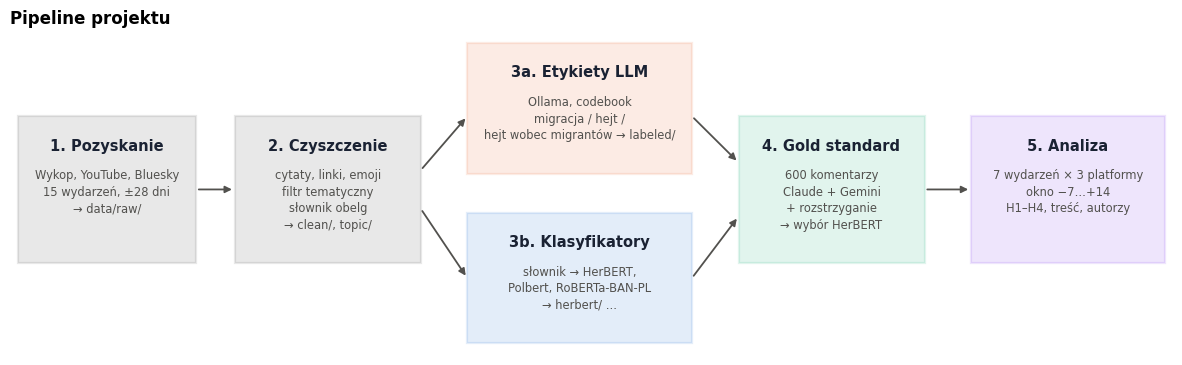

In [3]:
# schemat pipeline'u
fig, ax = plt.subplots(figsize=(15, 4.2))
ax.set_xlim(0, 15); ax.set_ylim(0, 4.2); ax.axis("off")
def box(x, y, w, h, title, sub, color):
    ax.add_patch(plt.Rectangle((x, y), w, h, facecolor=color, alpha=0.13, edgecolor=color, lw=1.6))
    ax.text(x + w / 2, y + h - 0.28, title, ha="center", va="top", fontsize=10.5, fontweight="bold", color=INK)
    ax.text(x + w / 2, y + h - 0.68, sub, ha="center", va="top", fontsize=8.3, color=INK2, linespacing=1.35)
def arrow(x1, y1, x2, y2):
    ax.annotate("", (x2, y2), (x1, y1), arrowprops=dict(arrowstyle="-|>", color=INK2, lw=1.3))
box(0.1, 1.2, 2.3, 1.9, "1. Pozyskanie", "Wykop, YouTube, Bluesky\n15 wydarzeń, ±28 dni\n→ data/raw/", "#52514e")
box(2.9, 1.2, 2.4, 1.9, "2. Czyszczenie", "cytaty, linki, emoji\nfiltr tematyczny\nsłownik obelg\n→ clean/, topic/", "#52514e")
box(5.9, 2.35, 2.9, 1.7, "3a. Etykiety LLM", "Ollama, codebook\nmigracja / hejt /\nhejt wobec migrantów → labeled/", "#eb6834")
box(5.9, 0.15, 2.9, 1.7, "3b. Klasyfikatory", "słownik → HerBERT,\nPolbert, RoBERTa-BAN-PL\n→ herbert/ …", "#2a78d6")
box(9.4, 1.2, 2.4, 1.9, "4. Gold standard", "600 komentarzy\nClaude + Gemini\n+ rozstrzyganie\n→ wybór HerBERT", "#1baf7a")
box(12.4, 1.2, 2.5, 1.9, "5. Analiza", "7 wydarzeń × 3 platformy\nokno −7…+14\nH1–H4, treść, autorzy", "#7c3aed")
arrow(2.4, 2.15, 2.9, 2.15); arrow(5.3, 2.4, 5.9, 3.1); arrow(5.3, 1.9, 5.9, 1.0)
arrow(8.8, 3.1, 9.4, 2.5); arrow(8.8, 1.0, 9.4, 1.8); arrow(11.8, 2.15, 12.4, 2.15)
ax.set_title("Pipeline projektu", loc="left")
savefig(fig, "1_pipeline"); plt.show()

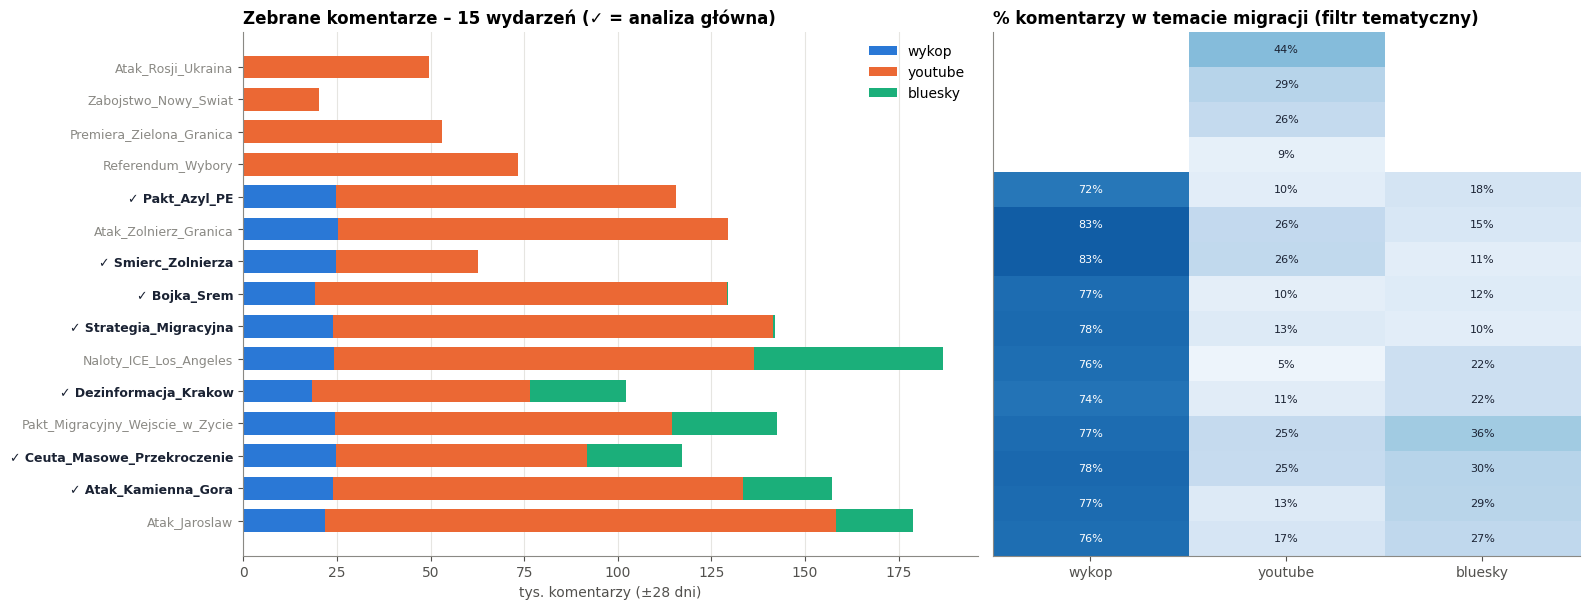

Łącznie zebrane komentarze (±28 dni, po czyszczeniu): 1,659,771 (wykop: 255,857, youtube: 1,228,811, bluesky: 175,103); w temacie migracji: 452,455.


In [4]:
# 15 wydarzeń: ile komentarzy zebraliśmy (cały okres ±28 dni) – z podsumowań predykcji HerBERT-a
vol = []
for p in PLATFORMS:
    f = ROOT / "data" / "interim" / p / "herbert_summary.csv"
    if f.exists():
        s = pd.read_csv(f, encoding="utf-8-sig")
        vol.append(s[["platform", "event", "clean", "topic"]])
if vol:
    vol = pd.concat(vol)
    folders = sorted(set(vol["event"]))                   # nazwy folderów zaczynają się od daty -> chronologicznie
    tab = vol.pivot_table(index="event", columns="platform", values="clean", aggfunc="sum").reindex(folders)[PLATFORMS]
    top = vol.pivot_table(index="event", columns="platform", values="topic", aggfunc="sum").reindex(folders)[PLATFORMS]
    tab.index = top.index = [f[11:] for f in folders]
    fig, axes = plt.subplots(1, 2, figsize=(16, 6.2), gridspec_kw={"width_ratios": [1.25, 1]})
    ax = axes[0]
    y = np.arange(len(tab))
    left = np.zeros(len(tab))
    for p in PLATFORMS:
        v = tab[p].fillna(0).values
        ax.barh(y, v / 1000, left=left, color=PLAT_COLORS[p], label=p, height=0.7)
        left += v / 1000
    labels = [f"{'✓ ' if e in EVENT_META else ''}{e}" for e in tab.index]
    ax.set_yticks(y, labels, fontsize=9); ax.invert_yaxis()
    for t, e in zip(ax.get_yticklabels(), tab.index):
        t.set_fontweight("bold" if e in EVENT_META else "normal"); t.set_color(INK if e in EVENT_META else MUTED)
    ax.grid(axis="x", visible=True); ax.grid(axis="y", visible=False)
    ax.set_xlabel("tys. komentarzy (±28 dni)"); ax.legend(loc="upper right")
    ax.set_title("Zebrane komentarze – 15 wydarzeń (✓ = analiza główna)")
    ax = axes[1]
    share = 100 * top / tab
    im = ax.imshow(share.values, cmap="Blues", aspect="auto", vmin=0, vmax=100)
    for (i, j), v in np.ndenumerate(share.values):
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0f}%", ha="center", va="center", fontsize=8, color="white" if v > 60 else INK)
    ax.set_xticks(range(len(PLATFORMS)), PLATFORMS); ax.set_yticks([]); ax.grid(False)
    ax.set_title("% komentarzy w temacie migracji (filtr tematyczny)")
    plt.tight_layout(); savefig(fig, "1_wydarzenia_wolumen"); plt.show()
    print(f"Łącznie zebrane komentarze (±28 dni, po czyszczeniu): {int(tab.sum().sum()):,} "
          f"({', '.join(f'{p}: {int(tab[p].sum()):,}' for p in PLATFORMS)}); w temacie migracji: {int(top.sum().sum()):,}.")

## 2. Jakość etykiet – gold standard

600 komentarzy (po 200 z platformy, z tych samych 7 wydarzeń), etykiety `hate` i `hate_migrants`. Szczegóły:
`notebooks/3_gold_standard/08_gold_standard_eval.ipynb` (klasyfikatory), `09_gold_standard_llm.ipynb` (LLM),
`10_hate_models_vs_llm.ipynb` (porównanie na tych samych komentarzach).

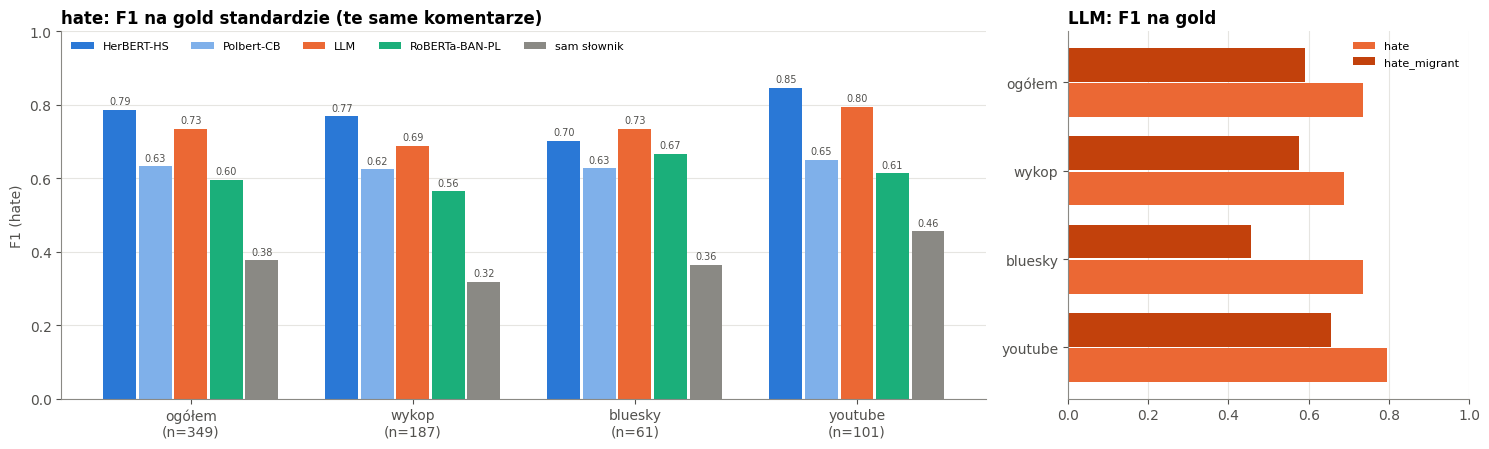

Najlepszy klasyfikator (600 komentarzy): HerBERT-HS – F1 0.78 [0.745, 0.814].
LLM: hate F1 0.735, hate_migrant F1 0.591 (LLM oceniany tylko na komentarzach z labeled/, czyli o migracji – jak w analizie).


In [5]:
gm = pd.read_csv(ROOT / "reports" / "gold_model_eval" / "model_metrics.csv")
cmp_p = ROOT / "reports" / "gold_llm_eval" / "hate_llm_vs_models.csv"
llm_p = ROOT / "reports" / "gold_llm_eval" / "llm_metrics.csv"
scopes = ["ogółem", "wykop", "bluesky", "youtube"]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [3, 1.3]})
if cmp_p.exists():
    cm = pd.read_csv(cmp_p)
    cm["zakres"] = cm["zakres"].replace({"wspólny podzbiór": "ogółem"})
    methods = ["HerBERT-HS", "Polbert-CB", "LLM (Ollama, labeled/)", "RoBERTa-BAN-PL", "sam słownik"]
    colors = ["#2a78d6", "#7fb0ea", "#eb6834", "#1baf7a", "#8a8984"]
    w = 0.8 / len(methods)
    for i, (m, col) in enumerate(zip(methods, colors)):
        e = cm[cm["metoda"] == m].set_index("zakres").reindex(scopes)
        x = np.arange(len(scopes)) + (i - (len(methods) - 1) / 2) * w
        axes[0].bar(x, e["f1"], w * 0.92, color=col, label=m.replace(" (Ollama, labeled/)", ""))
        for xi, v in zip(x, e["f1"]):
            axes[0].text(xi, v + 0.015, f"{v:.2f}", ha="center", fontsize=7, color=INK2)
    axes[0].set_xticks(range(len(scopes)), [f"{s}\n(n={int(cm[(cm.metoda == methods[0]) & (cm.zakres == s)]['n'].iloc[0])})" for s in scopes])
    axes[0].set_ylim(0, 1); axes[0].set_ylabel("F1 (hate)")
    axes[0].set_title("hate: F1 na gold standardzie (te same komentarze)"); axes[0].legend(ncol=5, fontsize=8, loc="upper left")
if llm_p.exists():
    lm = pd.read_csv(llm_p)
    t = lm[lm["zakres"].isin(scopes)].pivot_table(index="zakres", columns="etykieta", values="f1").reindex(scopes)
    y = np.arange(len(scopes))
    axes[1].barh(y + 0.2, t["hate"], 0.38, color="#eb6834", label="hate")
    axes[1].barh(y - 0.2, t["hate_migrant"], 0.38, color="#c2410c", label="hate_migrant")
    axes[1].set_yticks(y, scopes); axes[1].invert_yaxis(); axes[1].set_xlim(0, 1)
    axes[1].grid(axis="x", visible=True); axes[1].grid(axis="y", visible=False)
    axes[1].set_title("LLM: F1 na gold"); axes[1].legend(fontsize=8)
plt.tight_layout(); savefig(fig, "1_gold"); plt.show()
best_f1 = gm[(gm["wariant"] == "słownik + model") & (gm["zakres"] == "ogółem")].set_index("model")["f1"]
print(f"Najlepszy klasyfikator (600 komentarzy): {BEST['model']} – F1 {BEST['f1']} {BEST['f1_ci95']}.")
if llm_p.exists():
    print(f"LLM: hate F1 {t.loc['ogółem', 'hate']:.3f}, hate_migrant F1 {t.loc['ogółem', 'hate_migrant']:.3f} "
          "(LLM oceniany tylko na komentarzach z labeled/, czyli o migracji – jak w analizie).")

In [6]:
# zgodność anotatorów (Claude vs Gemini) przed rozstrzyganiem sporów – α Krippendorffa
agr_rows = []
for rnd in ["gold_v1", "gold_v2"]:
    f = ROOT / "data" / "annotation" / rnd / "results" / "agreement.json"
    if not f.exists():
        continue
    a = json.loads(f.read_text(encoding="utf-8"))
    for lab, key in [("hate", "hate"), ("hate_migrant", "hate_migrants")]:
        if key not in a:
            continue
        r = {"runda": rnd, "etykieta": lab, "n": a[key]["all"]["n_items"], "α ogółem": a[key]["all"]["alpha"],
             "95% CI": a[key]["all"]["alpha_ci95"], "pełna zgodność": a[key]["all"]["full_agreement"]}
        for p, v in a[key].get("by_platform", {}).items():
            r[f"α {p}"] = v["alpha"]
        agr_rows.append(r)
if agr_rows:
    print("Zgodność dwóch anotatorów-LLM przed rozstrzyganiem (α ≥ 0,667 = wystarczająca do wniosków wstępnych, ≥ 0,8 = dobra):")
    display(pd.DataFrame(agr_rows).set_index(["runda", "etykieta"]).round(3))
    print("Spory (ok. 1/5 komentarzy) rozstrzygano ręcznie – gold standard to wynik po rozstrzygnięciu.")
else:
    print("brak data/annotation/<runda>/results/agreement.json (dvc pull data/annotation) – pomijam zgodność")
gp = pd.read_csv(ROOT / "reports" / "gold_model_eval" / "gold_predictions.csv", encoding="utf-8-sig")
print("\nSkład gold standardu (% komentarzy z hejtem):",
      ", ".join(f"{p} {100 * v:.0f}%" for p, v in gp.groupby("platform")["gold"].mean().items()),
      f"| ogółem {100 * gp['gold'].mean():.0f}% (n = {len(gp)})")

Zgodność dwóch anotatorów-LLM przed rozstrzyganiem (α ≥ 0,667 = wystarczająca do wniosków wstępnych, ≥ 0,8 = dobra):


n  α ogółem          95% CI  pełna zgodność  α bluesky  α wykop  α youtube
runda   etykieta                                                                                  
gold_v1 hate          600     0.666  [0.604, 0.726]           0.833      0.578    0.606      0.725
        hate_migrant  600     0.722  [0.659, 0.787]           0.897      0.485    0.693      0.742

Spory (ok. 1/5 komentarzy) rozstrzygano ręcznie – gold standard to wynik po rozstrzygnięciu.

Skład gold standardu (% komentarzy z hejtem): bluesky 38%, wykop 60%, youtube 66% | ogółem 55% (n = 600)


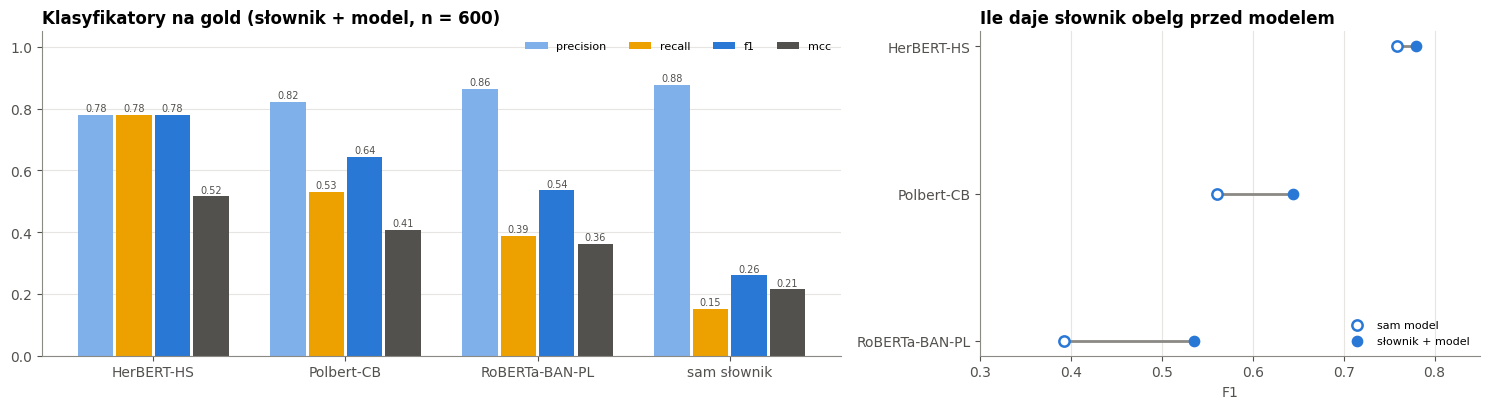

In [7]:
# precision / recall / F1 / MCC – słownik + model vs sam model
mm = gm[gm["zakres"] == "ogółem"].copy()
order_m = ["HerBERT-HS", "Polbert-CB", "RoBERTa-BAN-PL", "sam słownik"]
metrics = ["precision", "recall", "f1", "mcc"]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
w = 0.2
mcol = {"precision": "#7fb0ea", "recall": "#eda100", "f1": "#2a78d6", "mcc": "#52514e"}
sm_ = mm[mm["wariant"].isin(["słownik + model", "sam słownik"])].set_index("model").reindex(order_m)
for i, met in enumerate(metrics):
    x = np.arange(len(order_m)) + (i - 1.5) * w
    ax.bar(x, sm_[met], w * 0.92, color=mcol[met], label=met)
    for xi, v in zip(x, sm_[met]):
        ax.text(xi, v + 0.012, f"{v:.2f}", ha="center", fontsize=7, color=INK2)
ax.set_xticks(range(len(order_m)), order_m); ax.set_ylim(0, 1.05); ax.legend(ncol=4, fontsize=8, loc="upper right")
ax.set_title("Klasyfikatory na gold (słownik + model, n = 600)")
ax = axes[1]
pv = mm[mm["model"] != "sam słownik"].pivot_table(index="model", columns="wariant", values="f1").reindex(order_m[:3])
y = np.arange(len(pv))
ax.hlines(y, pv["sam model"], pv["słownik + model"], color=MUTED, lw=2)
ax.scatter(pv["sam model"], y, s=55, facecolor="white", edgecolor="#2a78d6", lw=1.8, zorder=3, label="sam model")
ax.scatter(pv["słownik + model"], y, s=55, color="#2a78d6", zorder=3, label="słownik + model")
ax.set_yticks(y, pv.index); ax.invert_yaxis(); ax.set_xlim(0.3, 0.85)
ax.grid(axis="x", visible=True); ax.grid(axis="y", visible=False); ax.legend(fontsize=8, loc="lower right")
ax.set_xlabel("F1"); ax.set_title("Ile daje słownik obelg przed modelem")
plt.tight_layout(); savefig(fig, "2_gold_metryki"); plt.show()

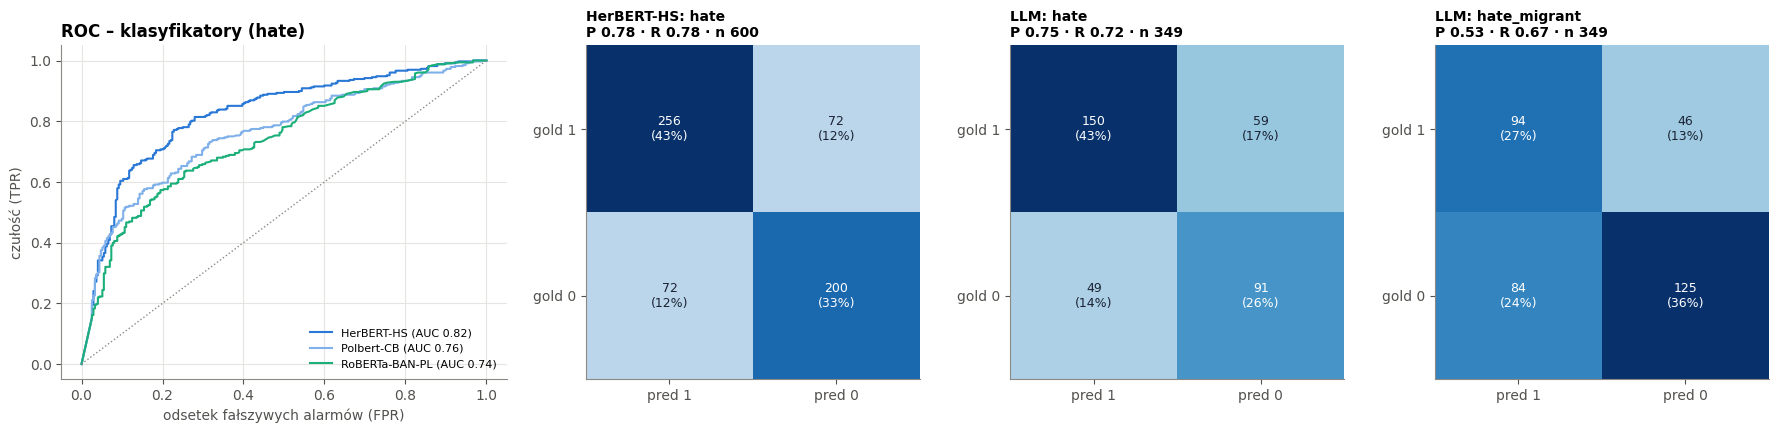

HerBERT: wszystkie 600 komentarzy gold; LLM: tylko komentarze gold z labeled/ (o migracji).


In [8]:
# krzywe ROC (score = max(prawdopodobieństwo modelu, słownik)) i macierze pomyłek: HerBERT vs LLM
def roc(y, s):
    o = np.argsort(-s, kind="mergesort"); y = np.asarray(y)[o]; s = np.asarray(s)[o]
    tps = np.cumsum(y); fps = np.cumsum(1 - y)
    keep = np.r_[np.diff(s) != 0, True]
    tpr = np.r_[0, tps[keep] / y.sum()]; fpr = np.r_[0, fps[keep] / (1 - y).sum()]
    return fpr, tpr, float(np.sum(np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2))

fig, axes = plt.subplots(1, 4, figsize=(18, 4.3), gridspec_kw={"width_ratios": [1.25, 1, 1, 1]})
ax = axes[0]
for m, col, name in [("herbert", "#2a78d6", "HerBERT-HS"), ("polbert", "#7fb0ea", "Polbert-CB"), ("roberta_banpl", "#1baf7a", "RoBERTa-BAN-PL")]:
    s = np.maximum(gp[f"prob_{m}"].fillna(0).values, gp["hate_auto"].values)
    fpr, tpr, auc = roc(gp["gold"].values, s)
    ax.plot(fpr, tpr, color=col, label=f"{name} (AUC {auc:.2f})")
ax.plot([0, 1], [0, 1], ls=":", color=MUTED, lw=1)
ax.set_xlabel("odsetek fałszywych alarmów (FPR)"); ax.set_ylabel("czułość (TPR)")
ax.grid(axis="x", visible=True); ax.legend(fontsize=8, loc="lower right"); ax.set_title("ROC – klasyfikatory (hate)")

def cm_plot(ax, y, p, title):
    m = np.array([[((y == 1) & (p == 1)).sum(), ((y == 1) & (p == 0)).sum()],
                  [((y == 0) & (p == 1)).sum(), ((y == 0) & (p == 0)).sum()]])
    ax.imshow(m, cmap="Blues", vmin=0, vmax=m.max())
    for (i, j), v in np.ndenumerate(m):
        ax.text(j, i, f"{v}\n({100 * v / m.sum():.0f}%)", ha="center", va="center", fontsize=9,
                color="white" if v > 0.6 * m.max() else INK)
    ax.set_xticks([0, 1], ["pred 1", "pred 0"]); ax.set_yticks([0, 1], ["gold 1", "gold 0"]); ax.grid(False)
    prec = m[0, 0] / max(1, m[0, 0] + m[1, 0]); rec = m[0, 0] / max(1, m[0, 0] + m[0, 1])
    ax.set_title(f"{title}\nP {prec:.2f} · R {rec:.2f} · n {m.sum()}", fontsize=10)

cm_plot(axes[1], gp["gold"].values, gp["pred_herbert"].values, "HerBERT-HS: hate")
gl_p = ROOT / "reports" / "gold_llm_eval" / "gold_llm_labels.csv"
if gl_p.exists():
    gl = pd.read_csv(gl_p, encoding="utf-8-sig")
    gl = gl[gl["llm_covered"].astype(str).str.lower().isin(["true", "1"])]
    cm_plot(axes[2], gl["gold_hate"].values, gl["llm_hate"].astype(int).values, "LLM: hate")
    cm_plot(axes[3], gl["gold_hate_migrant"].values, gl["llm_hate_migrant"].astype(int).values, "LLM: hate_migrant")
plt.tight_layout(); savefig(fig, "2_gold_roc_macierze"); plt.show()
print("HerBERT: wszystkie 600 komentarzy gold; LLM: tylko komentarze gold z labeled/ (o migracji).")

## 3. Dane do testów

Dla każdej komórki bazą są **komentarze o migracji** w oknie −7…+14 – te, które przeszły selekcję zespołu i są w `labeled/`:

- **YouTube / Bluesky** – cały `labeled/` (obelga ze słownika → od razu 1/1; reszta: filtr słów o migracji w komentarzu,
  wpisie lub komentarzu nadrzędnym, potem LLM „czy o migracji?”; zapisane są tylko komentarze o migracji),
- **Wykop** – komentarze z `topic/`, które LLM uznał za dotyczące migracji albo które zawierają obelgę ze słownika.

Komentarzy spoza tej selekcji **nie analizujemy** (nie dostają etykiety 0). Etykiety na tym samym zbiorze:
- `hate_migrant` – LLM: hejt wobec migrantów (YouTube / Bluesky także słownik, Wykop: LLM lub słownik),
- `hate (HerBERT)` – `hate_final` z `herbert/` (słownik obelg albo model, p ≥ 0,5); liczone na komentarzach, dla których
  jest predykcja HerBERT-a (≈ 100%).

In [9]:
def to_bool(s):
    return s.astype(str).str.strip().str.lower().isin(["true", "1", "1.0"])


def flag(d, cols):
    out = pd.Series(False, index=d.index)
    for c in cols:
        if c in d.columns:
            out |= to_bool(d[c])
    return out


def read_labeled(path):
    lab = pd.read_csv(path, encoding="utf-8-sig", dtype={"comment_id": str})
    if not isinstance(lab.index, pd.RangeIndex):      # bluesky:Atak_Kamienna_Gora – brak nazwy kolumny w nagłówku
        cols = list(lab.columns)
        i = cols.index("post_context") + 1
        lab = lab.reset_index()
        lab.columns = [*cols[:i], "parent_context", *cols[i:]]
        lab["comment_id"] = lab["comment_id"].astype(str)
    keep = [c for c in lab.columns if c in ("comment_id", "llm_is_about_migration", "llm_is_hate_migrants",
                                             "hate_migrants_auto", "model_hate_migrants", "human_hate_migrants")]
    return lab[keep].drop_duplicates("comment_id")


def load_cell(platform, event):
    d = ROOT / "data" / "interim" / platform / f"{EVENTS[event]}_{event}"
    lab_f = d / "labeled" / "comments_corrected.csv"
    if not lab_f.exists():
        lab_f = d / "labeled" / "comments.csv"
    if not lab_f.exists():
        return None, "brak etykiet LLM (labeled/)"
    clean = pd.read_csv(d / "clean" / "comments.csv", encoding="utf-8-sig", usecols=["comment_id", "relative_day", "thread_id", "author_id", "likes", "text"],
                        dtype={"comment_id": str, "thread_id": str, "author_id": str}).drop_duplicates("comment_id")
    clean = clean[clean["relative_day"].between(*WINDOW)]
    lab = read_labeled(lab_f)
    x = clean.merge(lab, on="comment_id", how="left", indicator=True)
    in_lab = x.pop("_merge").eq("both")
    if platform == "wykop":
        topic_ids = pd.read_csv(d / "topic" / "comments.csv", encoding="utf-8-sig", usecols=["comment_id"], dtype=str)["comment_id"]
        in_topic = in_lab & x["comment_id"].isin(topic_ids)
        # jak na YouTube / Bluesky: obelga ze słownika też wchodzi do komentarzy o migracji
        x["migrant"] = in_topic & flag(x, ["llm_is_about_migration", "hate_migrants_auto"])
        x["hate_migrant"] = in_topic & flag(x, ["llm_is_hate_migrants", "hate_migrants_auto"])
    else:
        x["migrant"] = in_lab
        x["hate_migrant"] = in_lab & flag(x, ["llm_is_hate_migrants", "model_hate_migrants", "human_hate_migrants"])
    hf = d / BEST["folder"] / "comments.csv"
    if hf.exists():
        h = pd.read_csv(hf, encoding="utf-8-sig", usecols=["comment_id", BEST["label_column"]], dtype={"comment_id": str})
        h = h.drop_duplicates("comment_id").set_index("comment_id")[BEST["label_column"]]
        x["herbert_ok"] = x["comment_id"].isin(h.index)
        x["hate_herbert"] = x["comment_id"].map(h).fillna(0).astype(int).astype(bool)
    else:
        x["herbert_ok"], x["hate_herbert"] = False, False
    n_all = len(x)
    # analizujemy tylko komentarze o migracji (to, czego nie ma w labeled/, pomijamy – nie jest zerem)
    x = x[x["migrant"]].copy()
    x["text"] = x["text"].fillna("").astype(str)
    x = x[["comment_id", "relative_day", "thread_id", "author_id", "likes", "text",
           "migrant", "hate_migrant", "herbert_ok", "hate_herbert"]].copy()
    x.attrs["n_all"] = n_all
    # id unikalne w obrębie platformy: YouTube i Bluesky – pseudonimy nadawane w każdym wydarzeniu od nowa
    x["uid"] = x["comment_id"] if platform == "wykop" else event + ":" + x["comment_id"]
    x["platform"], x["event"] = platform, event
    x["typ"], x["zasieg"] = EVENT_META[event]
    x["cell"] = f"{platform}:{event}"
    x["thread"] = x["cell"] + ":" + x["thread_id"].astype(str)
    x["po"] = (x["relative_day"] >= POST_FROM_DAY).astype(int)
    return x, None


frames, status = [], []
for platform in PLATFORMS:
    for event in EVENT_META:
        if (platform, event) in EXCLUDE:
            status.append({"platform": platform, "event": event, "status": "wykluczone (jak u zespołu)"})
            continue
        x, why = load_cell(platform, event)
        if x is None:
            status.append({"platform": platform, "event": event, "status": why})
            continue
        n_pre, n_post = int((x["po"] == 0).sum()), int((x["po"] == 1).sum())
        ok = n_pre >= MIN_N_PERIOD and n_post >= MIN_N_PERIOD
        status.append({"platform": platform, "event": event, "status": "w analizie" if ok else f"za mało komentarzy ({n_pre}/{n_post})",
                       "wszystkie komentarze w oknie": x.attrs["n_all"], "o migracji (analizowane)": len(x),
                       "przed": n_pre, "po": n_post, "hate_migrant": int(x["hate_migrant"].sum()),
                       "z predykcją HerBERT": int(x["herbert_ok"].sum()), "hate (HerBERT)": int(x["hate_herbert"].sum())})
        if ok:
            frames.append(x)
df = pd.concat(frames, ignore_index=True)
status = pd.DataFrame(status)
CELLS = list(dict.fromkeys(df["cell"]))
EVENT_ORDER = [e for e in EVENT_META if e in set(df["event"])]
COMMON = [e for e in EVENT_ORDER if all(f"{p}:{e}" in CELLS for p in PLATFORMS)]
display(status.set_index(["platform", "event"]))
print(f"komórek w analizie: {len(CELLS)} ({', '.join(f'{p}: {sum(c.startswith(p) for c in CELLS)}' for p in PLATFORMS)}) | "
      f"komentarzy: {len(df):,} | wydarzenia na wszystkich 3 platformach: {COMMON}")
missing_bs = status[(status["platform"] == "bluesky") & (status["status"] != "w analizie")]
if len(missing_bs):
    print(f"\nBluesky – pominięte (za mało komentarzy): {', '.join(missing_bs['event'])}")

status  wszystkie komentarze w oknie  o migracji (analizowane)   przed      po  hate_migrant  z predykcją HerBERT  hate (HerBERT)
platform event                                                                                                                                                                            
wykop    Pakt_Azyl_PE                                w analizie                       10412.0                    2586.0   532.0  2054.0        1087.0               2586.0          1161.0
         Smierc_Zolnierza                            w analizie                       10543.0                    4346.0  1256.0  3090.0        1754.0               4346.0          2076.0
         Bojka_Srem                                  w analizie                       10473.0                    3412.0   904.0  2508.0        1226.0               3412.0          1549.0
         Strategia_Migracyjna                        w analizie                        9551.0                    3930.0  1297.0  2633.0        1453.0               3930.0          1725.0
         Dezinformacja_Krakow                        w analizie                        7559.0                    2067.0   644.0  1423.0         855.0               2067.0           933.0
         Ceuta_Masowe_Przekroczenie                  w analizie                       10266.0                    4072.0  1370.0  2702.0        1771.0               4072.0          1954.0
         Atak_Kamienna_Gora                          w analizie                        9058.0                    2944.0  1178.0  1766.0        1311.0               2944.0          1440.0
youtube  Pakt_Azyl_PE                                w analizie                       87296.0                    1847.0   262.0  1585.0         891.0               1847.0          1125.0
         Smierc_Zolnierza            wykluczone (jak u zespołu)                           NaN                       NaN     NaN     NaN           NaN                  NaN             NaN
         Bojka_Srem                                  w analizie                      107271.0                    2397.0   549.0  1848.0        1569.0               2397.0          1569.0
         Strategia_Migracyjna                        w analizie                      114604.0                    4814.0   555.0  4259.0        2033.0               4814.0          2792.0
         Dezinformacja_Krakow                        w analizie                       54430.0                    1964.0   905.0  1059.0         930.0               1964.0          1217.0
         Ceuta_Masowe_Przekroczenie                  w analizie                       63939.0                    5922.0  1911.0  4011.0        3191.0               5922.0          3368.0
         Atak_Kamienna_Gora                          w analizie                      105881.0                    4998.0   432.0  4566.0        2967.0               4998.0          3010.0
bluesky  Pakt_Azyl_PE                  za mało komentarzy (0/0)                          74.0                       0.0     0.0     0.0           0.0                  0.0             0.0
         Smierc_Zolnierza              za mało komentarzy (0/0)                          48.0                       0.0     0.0     0.0           0.0                  0.0             0.0
         Bojka_Srem                    za mało komentarzy (0/6)                          64.0                       6.0     0.0     6.0           2.0                  6.0             1.0
         Strategia_Migracyjna          za mało komentarzy (0/5)                         359.0                       5.0     0.0     5.0           0.0                  5.0             0.0
         Dezinformacja_Krakow                        w analizie                        9236.0                     305.0   115.0   190.0          73.0                304.0            67.0
         Ceuta_Masowe_Przekroczenie                  w analizie                        9715.0                     621.0   271.0   

komórek w analizie: 16 (wykop: 7, youtube: 6, bluesky: 3) | komentarzy: 46,545 | wydarzenia na wszystkich 3 platformach: ['Dezinformacja_Krakow', 'Ceuta_Masowe_Przekroczenie', 'Atak_Kamienna_Gora']

Bluesky – pominięte (za mało komentarzy): Pakt_Azyl_PE, Smierc_Zolnierza, Bojka_Srem, Strategia_Migracyjna


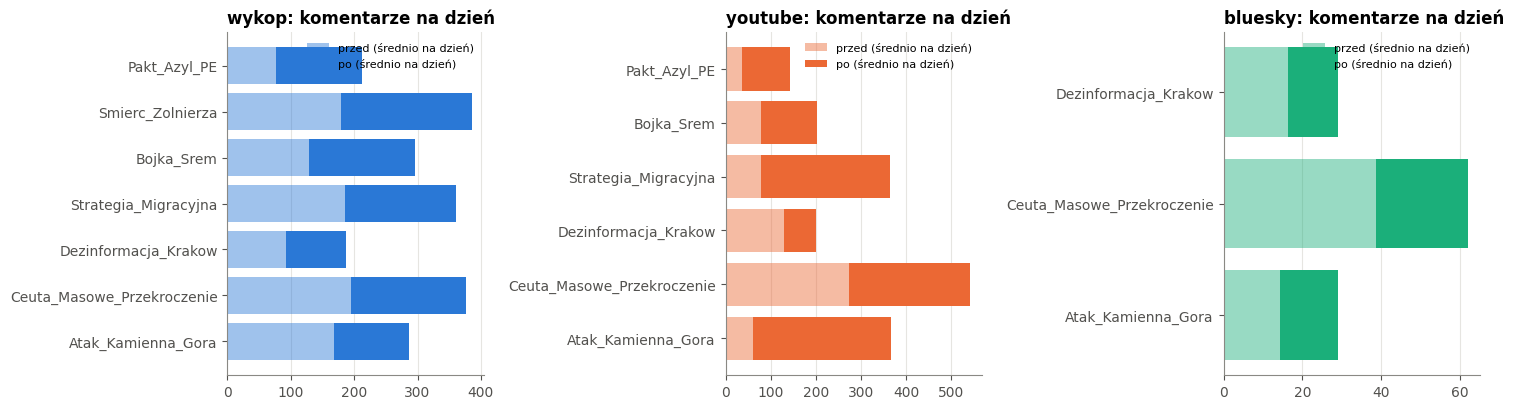

In [10]:
# wolumen danych: komentarze przed i po w każdej komórce
st = status[status["status"] == "w analizie"].copy()
st["cell"] = st["platform"] + ":" + st["event"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=False)
for ax, p in zip(axes, PLATFORMS):
    s = st[st["platform"] == p]
    if s.empty:
        ax.text(0.5, 0.5, "brak komórek", ha="center", va="center", transform=ax.transAxes, color=MUTED)
        ax.set_title(p); continue
    y = np.arange(len(s))
    ax.barh(y, s["przed"] / 7, color=PLAT_COLORS[p], alpha=0.45, label="przed (średnio na dzień)")
    ax.barh(y, s["po"] / 15, left=s["przed"] / 7, color=PLAT_COLORS[p], label="po (średnio na dzień)")
    ax.set_yticks(y, s["event"]); ax.invert_yaxis(); ax.grid(axis="x", visible=True); ax.grid(axis="y", visible=False)
    ax.set_title(f"{p}: komentarze na dzień"); ax.legend(fontsize=8)
plt.tight_layout(); savefig(fig, "0_dane_wolumen"); plt.show()

## 4. Efekt każdego wydarzenia (komórki) – podstawa wszystkich hipotez

Dla każdej komórki i miary: % przed i po, różnica w pp (95% CI Newcombe’a), OR z regresji logistycznej `y ~ po` z błędami
klastrowanymi po wątku, p z korektą Holma (w obrębie miary).

In [11]:
def cell_effect(d, num, den):
    g = d if den is None else d[d[den]]
    pre, post = g.loc[g["po"] == 0, num], g.loc[g["po"] == 1, num]
    n1, n2, k1, k2 = len(pre), len(post), int(pre.sum()), int(post.sum())
    row = {"n przed": n1, "n po": n2, "przed %": 100 * k1 / n1 if n1 else np.nan, "po %": 100 * k2 / n2 if n2 else np.nan}
    row["zmiana pp"] = row["po %"] - row["przed %"]
    if n1 < MIN_N_PERIOD or n2 < MIN_N_PERIOD:
        return row
    lo, hi = confint_proportions_2indep(k2, n2, k1, n1, method="newcomb")
    row.update({"CI lo": 100 * lo, "CI hi": 100 * hi})
    try:
        gg = g.assign(y=g[num].astype(int))
        m = smf.logit("y ~ po", data=gg).fit(disp=0, cov_type="cluster", cov_kwds={"groups": pd.factorize(gg["thread"])[0]})
        b, se = m.params["po"], m.bse["po"]
        row.update({"log OR": b, "se": se, "OR": np.exp(b), "OR lo": np.exp(b - 1.96 * se), "OR hi": np.exp(b + 1.96 * se),
                    "p": m.pvalues["po"]})
    except Exception:
        pass
    return row


rows = []
for cell, d in df.groupby("cell", sort=False):
    for meas, (num, den) in MEASURES.items():
        rows.append({"miara": meas, "cell": cell, "platform": d["platform"].iloc[0], "event": d["event"].iloc[0],
                     "typ": d["typ"].iloc[0], **cell_effect(d, num, den)})
eff = pd.DataFrame(rows)
eff["p (Holm)"] = np.nan
for meas, g in eff.groupby("miara"):
    ok = g["p"].notna()
    eff.loc[g.index[ok], "p (Holm)"] = multipletests(g.loc[ok, "p"], method="holm")[1]
eff["kierunek"] = np.where(eff["p (Holm)"] < ALPHA, np.where(eff["zmiana pp"] > 0, "↑", "↓"), "–")
eff.to_csv(OUT / "efekty_komorek.csv", index=False, encoding="utf-8-sig")
show = eff[eff["miara"] == MAIN][["platform", "event", "typ", "przed %", "po %", "zmiana pp", "CI lo", "CI hi", "OR", "p (Holm)", "kierunek"]]
print(f"Miara główna: {MEASURE_NAMES[MAIN]}")
display(fmt_p(show.set_index(["platform", "event"]), 2))

Miara główna: hejt wobec migrantów (LLM)


typ  przed %   po %  zmiana pp  CI lo  CI hi    OR  p (Holm) kierunek
platform event                                                                                                         
wykop    Pakt_Azyl_PE                      polityczne    39.10  42.79       3.70  -1.02   8.29  1.17         1        –
         Smierc_Zolnierza                  kryminalne    43.07  39.26      -3.82  -7.06  -0.60  0.85         1        –
         Bojka_Srem                        kryminalne    38.83  34.89      -3.94  -7.65  -0.29  0.84         1        –
         Strategia_Migracyjna              polityczne    39.32  35.81      -3.51  -6.75  -0.30  0.86         1        –
         Dezinformacja_Krakow           dezinformacja    40.22  41.88       1.67  -2.93   6.19  1.07         1        –
         Ceuta_Masowe_Przekroczenie  kryzys graniczny    47.59  41.41      -6.18  -9.40  -2.95  0.78      0.31        –
         Atak_Kamienna_Gora                kryminalne    44.14  44.79       0.65  -3.02   4.30  1.03         1        –
youtube  Pakt_Azyl_PE                      polityczne    68.70  44.86     -23.84 -29.69 -17.50  0.37    0.0493        ↓
         Bojka_Srem                        kryminalne    75.05  62.61     -12.44 -16.53  -8.07  0.56     0.916        –
         Strategia_Migracyjna              polityczne    58.92  40.06     -18.86 -23.14 -14.47  0.47  0.000977        ↓
         Dezinformacja_Krakow           dezinformacja    49.83  45.23      -4.60  -9.01  -0.17  0.83         1        –
         Ceuta_Masowe_Przekroczenie  kryzys graniczny    67.14  47.57     -19.57 -22.15 -16.93  0.44      0.31        –
         Atak_Kamienna_Gora                kryminalne    36.11  61.56      25.45  20.61  30.06  2.83    0.0342        ↑
bluesky  Dezinformacja_Krakow           dezinformacja    26.09  22.63      -3.46 -13.69   6.19  0.83         1        –
         Ceuta_Masowe_Przekroczenie  kryzys graniczny    47.23  37.14     -10.09 -17.79  -2.27  0.66         1        –
         Atak_Kamienna_Gora                kryminalne    27.72  27.85       0.13 -10.79  10.14  1.01         1        –

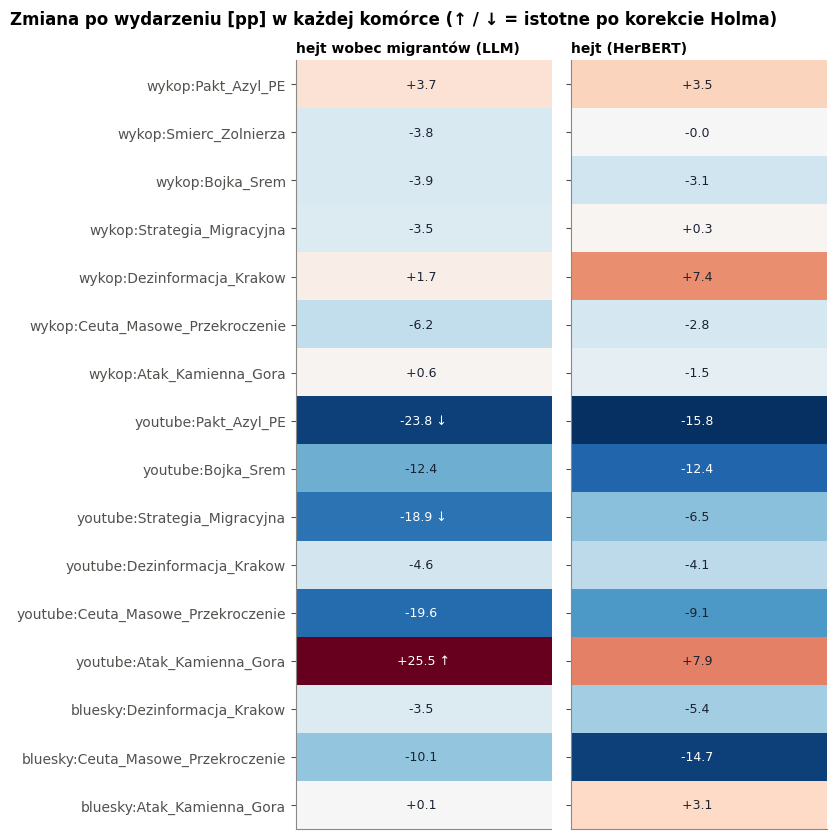

In [12]:
# mapa zmian: komórki × miary (liczba = zmiana pp, ↑/↓ = istotne po Holmie)
fig, axes = plt.subplots(1, len(MEASURES), figsize=(4.2 * len(MEASURES), 0.42 * len(CELLS) + 1.8), sharey=True)
for ax, meas in zip(axes, MEASURES):
    e = eff[eff["miara"] == meas].set_index("cell").reindex(CELLS)
    v = e["zmiana pp"].values.reshape(-1, 1)
    lim = np.nanmax(np.abs(v)) or 1
    ax.imshow(v, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
    for i, (val, k) in enumerate(zip(e["zmiana pp"], e["kierunek"])):
        if pd.notna(val):
            ax.text(0, i, f"{val:+.1f} {k if k != '–' else ''}", ha="center", va="center", fontsize=9,
                    color="white" if abs(val) > 0.6 * lim else INK)
    ax.set_xticks([]); ax.set_title(MEASURE_NAMES[meas], fontsize=10)
    ax.set_yticks(range(len(CELLS)), CELLS); ax.grid(False)
fig.suptitle("Zmiana po wydarzeniu [pp] w każdej komórce (↑ / ↓ = istotne po korekcie Holma)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); savefig(fig, "2_mapa_zmian"); plt.show()

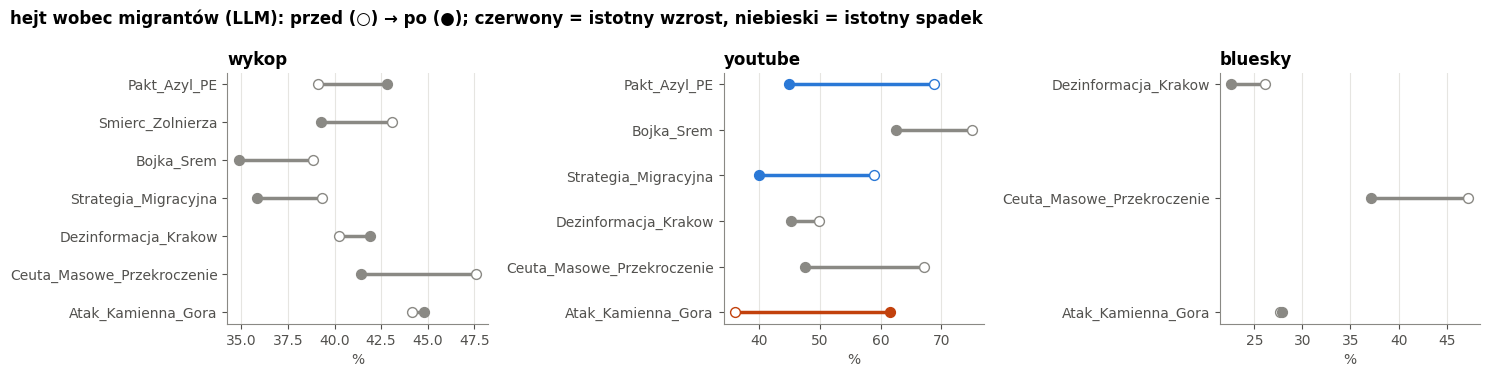

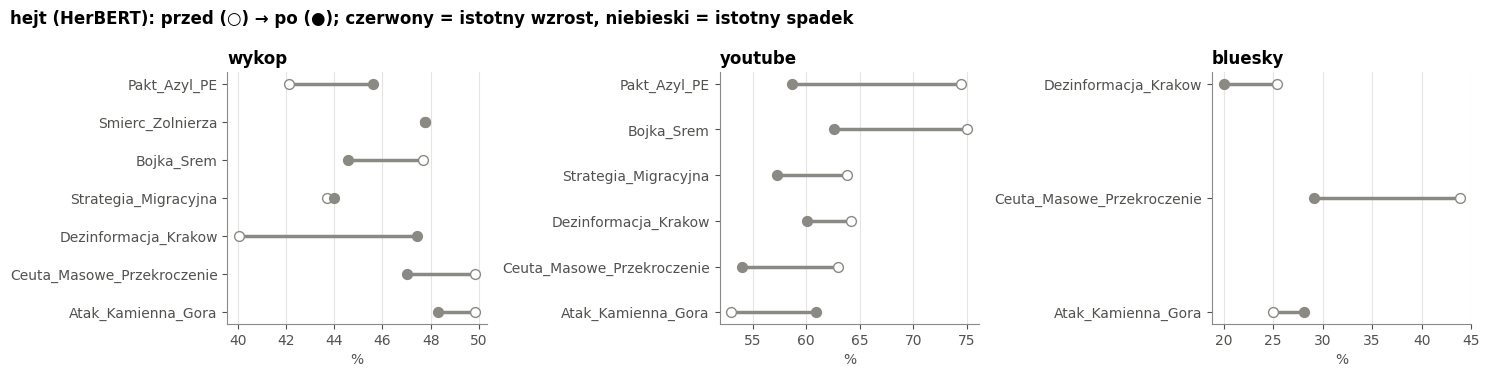

In [13]:
# dumbbell: % przed -> po dla miary głównej i HerBERT, panel per platforma
for meas in [MAIN, "hate (HerBERT)"]:
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
    for ax, p in zip(axes, PLATFORMS):
        e = eff[(eff["miara"] == meas) & (eff["platform"] == p)]
        if e.empty:
            ax.text(0.5, 0.5, "brak", ha="center", va="center",
                    transform=ax.transAxes, color=MUTED); ax.set_title(p); continue
        y = np.arange(len(e))
        for yi, (_, r) in zip(y, e.iterrows()):
            col = "#c2410c" if r["kierunek"] == "↑" else ("#2a78d6" if r["kierunek"] == "↓" else MUTED)
            ax.plot([r["przed %"], r["po %"]], [yi, yi], color=col, lw=2.5)
            ax.scatter(r["przed %"], yi, s=50, facecolor="white", edgecolor=col, zorder=3)
            ax.scatter(r["po %"], yi, s=50, color=col, zorder=3)
        ax.set_yticks(y, e["event"]); ax.invert_yaxis(); ax.grid(axis="x", visible=True); ax.grid(axis="y", visible=False)
        ax.set_title(p); ax.set_xlabel("%")
    fig.suptitle(f"{MEASURE_NAMES[meas]}: przed (○) → po (●); czerwony = istotny wzrost, niebieski = istotny spadek",
                 x=0.01, ha="left", fontweight="bold")
    plt.tight_layout(); savefig(fig, f"2_dumbbell_{'llm' if meas == MAIN else 'herbert'}"); plt.show()

## 5. H1 – czy wydarzenia zmieniają poziom hejtu?

**Test z README:** Wilcoxon dla par (średni dzienny odsetek przed vs po w każdej komórce) + wielkość efektu
(korelacja rangowo-dwuseryjna *r*: 0,1 mały, 0,3 średni, 0,5 duży). Liczone dla wszystkich komórek i dla każdej platformy.
**Wspierająco:** metaanaliza efektów losowych OR komórek (DerSimonian–Laird + Hartung–Knapp) – jak w analizie zespołu.

In [14]:
def daily_shares(d, num, den):
    g = d if den is None else d[d[den]]
    t = g.groupby("relative_day").agg(n=(num, "size"), k=(num, "sum"))
    t = t[t["n"] >= MIN_DAILY_N]
    return 100 * t["k"] / t["n"]


def wilcoxon_pairs(a, b):
    d = np.asarray(b, float) - np.asarray(a, float)
    d = d[~np.isnan(d) & (d != 0)]
    if len(d) < 3:
        return {"n": len(d), "p": np.nan, "r": np.nan}
    ranks = stats.rankdata(np.abs(d))
    return {"n": len(d), "p": stats.wilcoxon(d).pvalue, "r": (ranks[d > 0].sum() - ranks[d < 0].sum()) / ranks.sum()}


def meta_random(y, se):
    y, se = np.asarray(y, float), np.asarray(se, float)
    ok = ~np.isnan(y) & ~np.isnan(se) & (se > 0)
    y, se = y[ok], se[ok]
    k = len(y)
    if k == 0:
        return {"k": 0}
    w = 1 / se ** 2
    q = (w * (y - (w * y).sum() / w.sum()) ** 2).sum()
    tau2 = max(0.0, (q - (k - 1)) / (w.sum() - (w ** 2).sum() / w.sum())) if k > 1 else 0.0
    ws = 1 / (se ** 2 + tau2)
    mu = (ws * y).sum() / ws.sum()
    if k == 1:
        return {"k": 1, "OR": np.exp(mu), "OR lo": np.exp(mu - 1.96 * se[0]), "OR hi": np.exp(mu + 1.96 * se[0]),
                "p meta": 2 * stats.norm.sf(abs(mu / se[0])), "I²": np.nan}
    se_hk = max(np.sqrt((ws * (y - mu) ** 2).sum() / ((k - 1) * ws.sum())), np.sqrt(1 / ws.sum()))
    t = stats.t.ppf(0.975, k - 1)
    return {"k": k, "OR": np.exp(mu), "OR lo": np.exp(mu - t * se_hk), "OR hi": np.exp(mu + t * se_hk),
            "p meta": 2 * stats.t.sf(abs(mu / se_hk), k - 1), "I²": max(0.0, (q - (k - 1)) / q) if q > 0 else 0.0}


pp_rows = []
for cell, d in df.groupby("cell", sort=False):
    for meas, (num, den) in MEASURES.items():
        s = daily_shares(d, num, den)
        pre, post = s[s.index < POST_FROM_DAY], s[s.index >= POST_FROM_DAY]
        pp_rows.append({"miara": meas, "cell": cell, "platform": d["platform"].iloc[0], "event": d["event"].iloc[0],
                        "typ": d["typ"].iloc[0], "przed": pre.mean() if len(pre) else np.nan,
                        "po": post.mean() if len(post) else np.nan})
pp = pd.DataFrame(pp_rows)
pp["zmiana"] = pp["po"] - pp["przed"]

h1_rows = []
for meas in MEASURES:
    for scope in ["wszystkie"] + PLATFORMS:
        s = pp[(pp["miara"] == meas) & ((pp["platform"] == scope) | (scope == "wszystkie"))].dropna(subset=["przed", "po"])
        e = eff[(eff["miara"] == meas) & ((eff["platform"] == scope) | (scope == "wszystkie"))]
        if s.empty:
            continue
        w = wilcoxon_pairs(s["przed"], s["po"])
        mt = meta_random(e["log OR"], e["se"])
        h1_rows.append({"miara": meas, "zakres": scope, "komórek": len(s), "wzrost w": f"{int((s['zmiana'] > 0).sum())}/{len(s)}",
                        "istotnie ↑/↓": f"{int((e['kierunek'] == '↑').sum())}/{int((e['kierunek'] == '↓').sum())}",
                        "mediana zmiany pp": s["zmiana"].median(), "p Wilcoxon": w["p"], "r": w["r"],
                        "OR meta": mt.get("OR"), "OR lo": mt.get("OR lo"), "OR hi": mt.get("OR hi"), "p meta": mt.get("p meta"),
                        "I²": mt.get("I²")})
h1 = pd.DataFrame(h1_rows)
h1.to_csv(OUT / "h1.csv", index=False, encoding="utf-8-sig")
display(fmt_p(h1.set_index(["miara", "zakres"]), 3))

komórek wzrost w istotnie ↑/↓  mediana zmiany pp p Wilcoxon      r  OR meta  OR lo  OR hi  p meta     I²
miara          zakres                                                                                                             
hate_migrant   wszystkie       16     7/16          1/2             -3.245      0.231 -0.353    0.835  0.672  1.036  0.0956  0.671
               wykop            7      3/7          0/0             -2.863      0.219 -0.571    0.926  0.804  1.066   0.228  0.333
               youtube          6      2/6          1/2            -11.095      0.438 -0.429    0.673  0.307  1.477   0.252  0.806
               bluesky          3      2/3          0/0              2.205          1  0.000    0.793  0.320  1.967   0.387  0.000
hate (HerBERT) wszystkie       16     6/16          0/0             -1.036      0.348 -0.279    0.897  0.771  1.045   0.151  0.557
               wykop            7      3/7          0/0             -0.326      0.938 -0.071    0.999  0.878  1.135   0.979  0.231
               youtube          6      2/6          0/0             -6.213      0.156 -0.714    0.749  0.511  1.099    0.11  0.565
               bluesky          3      1/3          0/0             -0.792       0.75 -0.333    0.742  0.265  2.081   0.339  0.565

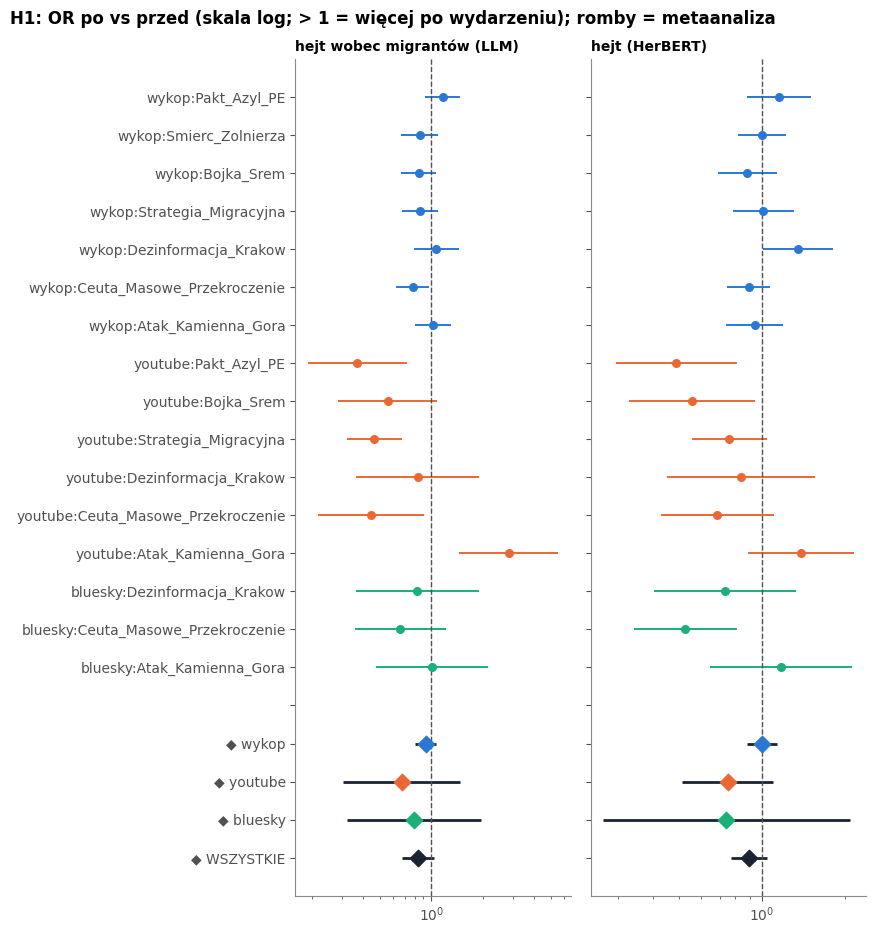

In [15]:
# las: OR komórek (kropki) + łączny OR platform i wszystkich (romby), dla obu miar
fig, axes = plt.subplots(1, len(MEASURES), figsize=(4.4 * len(MEASURES), 0.38 * (len(CELLS) + 5) + 1.5), sharey=True)
labels = CELLS + ["", *[f"◆ {p}" for p in PLATFORMS], "◆ WSZYSTKIE"]
ypos = {lab: i for i, lab in enumerate(labels)}
for ax, meas in zip(axes, MEASURES):
    e = eff[eff["miara"] == meas].set_index("cell")
    for c in CELLS:
        if c in e.index and pd.notna(e.loc[c, "OR"]):
            r = e.loc[c]
            col = PLAT_COLORS[r["platform"]]
            ax.hlines(ypos[c], r["OR lo"], r["OR hi"], color=col, lw=1.4)
            ax.scatter(r["OR"], ypos[c], color=col, s=30, zorder=3)
    for scope in PLATFORMS + ["wszystkie"]:
        rr = h1[(h1["miara"] == meas) & (h1["zakres"] == scope)]
        if rr.empty or pd.isna(rr["OR meta"].iloc[0]):
            continue
        r = rr.iloc[0]
        y = ypos["◆ WSZYSTKIE" if scope == "wszystkie" else f"◆ {scope}"]
        ax.hlines(y, r["OR lo"], r["OR hi"], color=INK, lw=2)
        ax.scatter(r["OR meta"], y, marker="D", s=70, color=INK if scope == "wszystkie" else PLAT_COLORS[scope], zorder=3)
    ax.axvline(1, ls="--", color=INK2, lw=1); ax.set_xscale("log")
    ax.set_title(MEASURE_NAMES[meas], fontsize=10); ax.grid(axis="x", visible=True); ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(labels)), labels); axes[0].invert_yaxis()
fig.suptitle("H1: OR po vs przed (skala log; > 1 = więcej po wydarzeniu); romby = metaanaliza", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); savefig(fig, "3_h1_las"); plt.show()

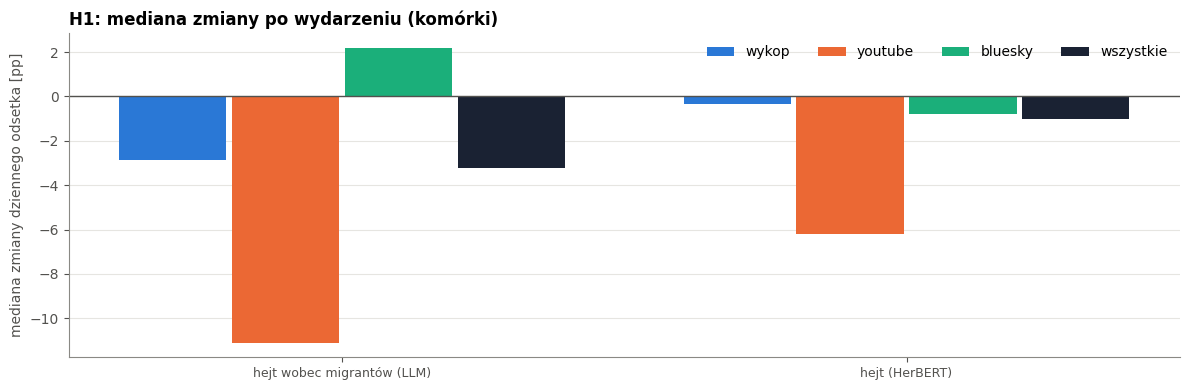

In [16]:
# H1 jednym rzutem oka: mediana zmiany i odsetek komórek ze wzrostem, per miara i platforma
fig, ax = plt.subplots(figsize=(12, 4))
xs = np.arange(len(MEASURES))
for i, p in enumerate(PLATFORMS + ["wszystkie"]):
    vals = [h1[(h1["miara"] == m) & (h1["zakres"] == p)]["mediana zmiany pp"].iloc[0]
            if len(h1[(h1["miara"] == m) & (h1["zakres"] == p)]) else np.nan for m in MEASURES]
    ax.bar(xs + (i - 1.5) * 0.2, vals, 0.19, color=PLAT_COLORS.get(p, INK), label=p)
ax.axhline(0, color=INK2, lw=1)
ax.set_xticks(xs, [MEASURE_NAMES[m] for m in MEASURES], fontsize=9)
ax.set_ylabel("mediana zmiany dziennego odsetka [pp]")
ax.set_title("H1: mediana zmiany po wydarzeniu (komórki)"); ax.legend(ncol=4)
plt.tight_layout(); savefig(fig, "3_h1_mediany"); plt.show()

## 6. H2 – czy siła zmiany zależy od charakteru wydarzenia?

**Test z README:** Kruskal–Wallis na zmianie (pp) komórek między typami wydarzeń → post-hoc Dunn + Holm; wielkość efektu ε².
Typy jak w analizie zespołu. ⚠️ Typy „dezinformacja” i „kryzys graniczny” mają po jednym wydarzeniu, więc efekt typu jest tam
nieodróżnialny od efektu wydarzenia – wynik eksploracyjny.

,H,p,ε²,grup,n,mediana kryminalne,mediana polityczne,mediana dezinformacja,mediana kryzys graniczny
miara,,,,,,,,,
hate_migrant,7.173,0.0666,0.348,4,16,-0.938,-9.367,2.205,-15.574
hate (HerBERT),5.831,0.12,0.236,4,16,-0.803,-3.019,5.241,-8.641


Post-hoc Dunn + Holm (miara główna):


,A,B,z,p,p (Holm)
0,dezinformacja,kryminalne,0.693,0.488,0.955
1,dezinformacja,kryzys graniczny,2.315,0.0206,0.124
2,dezinformacja,polityczne,1.765,0.0776,0.31
3,kryminalne,kryzys graniczny,1.980,0.0477,0.238
4,kryminalne,polityczne,1.329,0.184,0.552
5,kryzys graniczny,polityczne,-0.710,0.477,0.955


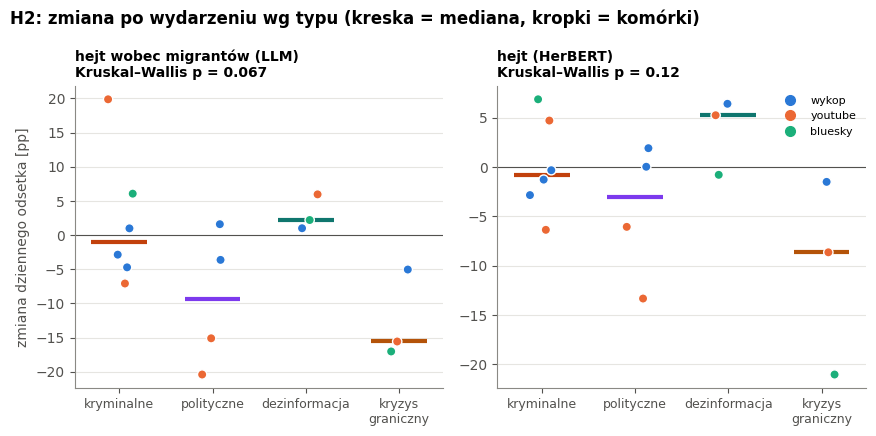

In [17]:
def dunn(groups, labels):
    allv = np.concatenate(groups)
    ranks = stats.rankdata(allv)
    n = len(allv)
    _, cnt = np.unique(allv, return_counts=True)
    tie = 1 - (cnt ** 3 - cnt).sum() / (n ** 3 - n) if n > 1 else 1
    means, i0 = [], 0
    for g in groups:
        means.append(ranks[i0:i0 + len(g)].mean()); i0 += len(g)
    out = []
    for (i, a), (j, b) in combinations(enumerate(labels), 2):
        se = np.sqrt(tie * n * (n + 1) / 12 * (1 / len(groups[i]) + 1 / len(groups[j])))
        z = (means[i] - means[j]) / se
        out.append({"A": a, "B": b, "z": z, "p": 2 * stats.norm.sf(abs(z))})
    r = pd.DataFrame(out)
    if len(r):
        r["p (Holm)"] = multipletests(r["p"], method="holm")[1]
    return r


def kw(data, by, value="zmiana"):
    g = {k: v[value].dropna().values for k, v in data.groupby(by) if v[value].notna().sum() >= 1}
    g = {k: v for k, v in g.items() if len(v)}
    if len(g) < 2 or sum(len(v) for v in g.values()) <= len(g):
        return {"H": np.nan, "p": np.nan, "ε²": np.nan, "grup": len(g)}, None
    h, p = stats.kruskal(*g.values())
    n = sum(len(v) for v in g.values())
    return {"H": h, "p": p, "ε²": (h - len(g) + 1) / (n - len(g)), "grup": len(g), "n": n}, dunn(list(g.values()), list(g.keys()))


h2_rows, h2_post = [], {}
for meas in MEASURES:
    s = pp[pp["miara"] == meas]
    res, post = kw(s, "typ")
    med = s.groupby("typ")["zmiana"].median()
    h2_rows.append({"miara": meas, **res, **{f"mediana {t}": med.get(t, np.nan) for t in TYPE_ORDER}})
    h2_post[meas] = post
h2 = pd.DataFrame(h2_rows)
h2.to_csv(OUT / "h2.csv", index=False, encoding="utf-8-sig")
display(fmt_p(h2.set_index("miara"), 3))
print("Post-hoc Dunn + Holm (miara główna):")
if h2_post[MAIN] is not None:
    display(fmt_p(h2_post[MAIN], 3))

fig, axes = plt.subplots(1, len(MEASURES), figsize=(4.4 * len(MEASURES), 4.4), sharey=False)
rng = np.random.default_rng(SEED)
for ax, meas in zip(axes, MEASURES):
    s = pp[pp["miara"] == meas]
    for xi, t in enumerate(TYPE_ORDER):
        g = s[s["typ"] == t]
        if g.empty:
            continue
        xs = xi + rng.uniform(-0.15, 0.15, len(g))
        ax.scatter(xs, g["zmiana"], c=[PLAT_COLORS[p] for p in g["platform"]], s=45, edgecolor="white", zorder=3)
        ax.hlines(g["zmiana"].median(), xi - 0.3, xi + 0.3, color=TYPE_COLORS[t], lw=3)
    ax.axhline(0, color=INK2, lw=0.8)
    ax.set_xticks(range(len(TYPE_ORDER)), [t.replace(" ", "\n") for t in TYPE_ORDER], fontsize=9)
    p_kw = h2.set_index("miara").loc[meas, "p"]
    ax.set_title(f"{MEASURE_NAMES[meas]}\nKruskal–Wallis p = {p_kw:.2g}", fontsize=10)
axes[0].set_ylabel("zmiana dziennego odsetka [pp]")
handles = [plt.Line2D([], [], marker="o", ls="", color=c, ms=7) for c in PLAT_COLORS.values()]
axes[-1].legend(handles, PLAT_COLORS.keys(), loc="upper right", fontsize=8)
fig.suptitle("H2: zmiana po wydarzeniu wg typu (kreska = mediana, kropki = komórki)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); savefig(fig, "4_h2_typy"); plt.show()

## 7. H3 – czy zmiana jest największa tuż po wydarzeniu i potem słabnie?

**Testy z README:** dla każdej komórki zmiana odsetka w oknach **0–3, 4–7, 8–14 dni** względem baseline (−7…−1).
- **Friedman** – czy okna różnią się między sobą (te same komórki), post-hoc **Wilcoxon + Holm** dla par okien,
- **każde okno vs baseline** – Wilcoxon (zmiana ≠ 0) + Holm: po ilu dniach efekt przestaje być widoczny.

H3 byłaby potwierdzona, gdyby okno 0–3 miało największą zmianę, a kolejne okna – coraz mniejszą (wracając do baseline).

In [18]:
def window_share(g, num, lo, hi):
    w = g[g["relative_day"].between(lo, hi)]
    return (100 * w[num].mean(), len(w)) if len(w) else (np.nan, 0)


wrows = []
for cell, d in df.groupby("cell", sort=False):
    for meas, (num, den) in MEASURES.items():
        g = d if den is None else d[d[den]]
        b, nb = window_share(g, num, WINDOW[0], POST_FROM_DAY - 1)
        row = {"miara": meas, "cell": cell, "platform": d["platform"].iloc[0], "baseline %": b}
        for name, (lo, hi) in H3_WINDOWS.items():
            s, n = window_share(g, num, lo, hi)
            row[name] = s - b if (n >= MIN_N_PERIOD / 2 and nb >= MIN_N_PERIOD) else np.nan
        wrows.append(row)
win = pd.DataFrame(wrows)
win.to_csv(OUT / "h3_okna.csv", index=False, encoding="utf-8-sig")
WN = list(H3_WINDOWS)

h3_rows, h3_pairs = [], []
for meas in MEASURES:
    for scope in ["wszystkie"] + PLATFORMS:
        s = win[(win["miara"] == meas) & ((win["platform"] == scope) | (scope == "wszystkie"))].dropna(subset=WN)
        if len(s) < 3:
            continue
        fr = stats.friedmanchisquare(*[s[w] for w in WN])
        ps = [stats.wilcoxon(s[w]).pvalue if (s[w] != 0).sum() >= 3 else np.nan for w in WN]
        ok = [p for p in ps if pd.notna(p)]
        holm = list(multipletests(ok, method="holm")[1]) if ok else []
        ph = [holm.pop(0) if pd.notna(p) else np.nan for p in ps]
        h3_rows.append({"miara": meas, "zakres": scope, "komórek": len(s), "p Friedman": fr.pvalue,
                        **{f"{w}: średnio pp": s[w].mean() for w in WN},
                        **{f"p (Holm) {w} vs baseline": v for w, v in zip(WN, ph)}})
        if scope == "wszystkie":
            pr = []
            for a, b in combinations(WN, 2):
                dlt = s[b] - s[a]
                pr.append({"miara": meas, "okno A": a, "okno B": b, "mediana B−A pp": dlt.median(),
                           "p": stats.wilcoxon(dlt).pvalue if (dlt != 0).sum() >= 3 else np.nan})
            pr = pd.DataFrame(pr)
            pr["p (Holm)"] = multipletests(pr["p"].fillna(1), method="holm")[1]
            h3_pairs.append(pr)
h3 = pd.DataFrame(h3_rows)
h3.to_csv(OUT / "h3.csv", index=False, encoding="utf-8-sig")
display(fmt_p(h3.set_index(["miara", "zakres"]), 3))
print("Post-hoc: Wilcoxon między oknami + Holm (wszystkie komórki)")
display(fmt_p(pd.concat(h3_pairs).set_index(["miara", "okno A", "okno B"]), 3))

komórek p Friedman  dni 0–3: średnio pp  dni 4–7: średnio pp  dni 8–14: średnio pp p (Holm) dni 0–3 vs baseline p (Holm) dni 4–7 vs baseline p (Holm) dni 8–14 vs baseline
miara          zakres                                                                                                                                                                               
hate_migrant   wszystkie       16      0.174               -6.011               -6.902                -2.674                        0.167                        0.133                         0.167
               wykop            7      0.368               -1.647               -3.825                -0.390                        0.938                        0.891                         0.938
               youtube          6      0.311              -10.590              -11.354                -4.282                        0.469                        0.469                         0.469
               bluesky          3          1               -7.036               -5.175                -4.784                         0.75                            1                             1
hate (HerBERT) wszystkie       16       0.57               -2.092               -4.451                -2.201                        0.462                       0.0547                         0.462
               wykop            7      0.368               -0.257               -1.121                 2.014                            1                            1                             1
               youtube          6      0.846               -5.208               -8.789                -4.331                        0.438                       0.0938                         0.438
               bluesky          3      0.368               -0.139               -3.548                -7.774                            1                         0.75                          0.75

Post-hoc: Wilcoxon między oknami + Holm (wszystkie komórki)


mediana B−A pp      p p (Holm)
miara          okno A  okno B                                  
hate_migrant   dni 0–3 dni 4–7           -1.056  0.632    0.632
                       dni 8–14           3.413  0.193    0.389
               dni 4–7 dni 8–14           4.187   0.13    0.389
hate (HerBERT) dni 0–3 dni 4–7            1.749  0.744        1
                       dni 8–14           2.914  0.632        1
               dni 4–7 dni 8–14           2.747  0.231    0.694

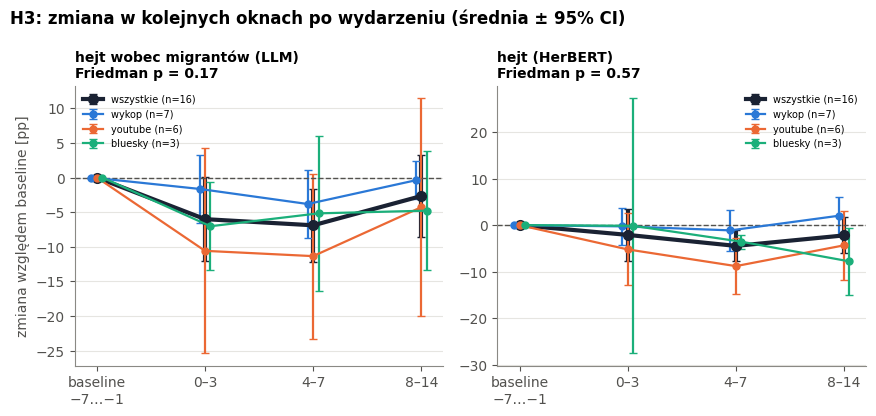

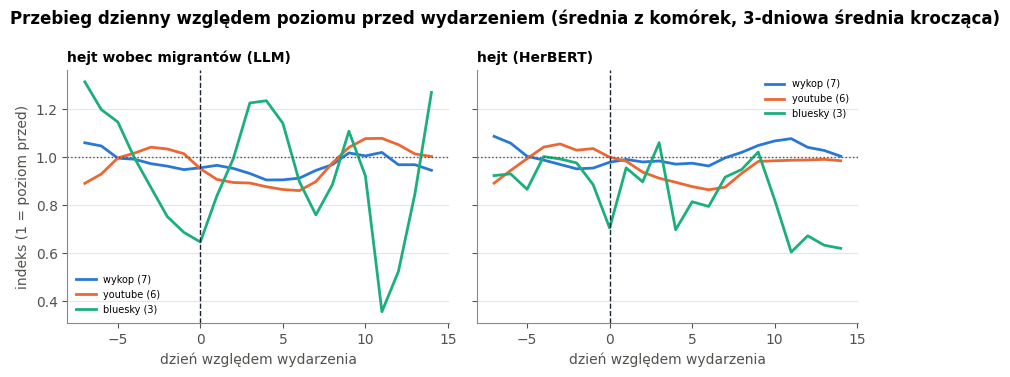

In [19]:
# H3: średnia zmiana w oknach (± 95% CI) – wszystkie komórki i per platforma
fig, axes = plt.subplots(1, len(MEASURES), figsize=(4.4 * len(MEASURES), 4.2), sharey=False)
x = np.arange(len(WN) + 1)
for ax, meas in zip(axes, MEASURES):
    for scope, col, lw in [("wszystkie", INK, 3)] + [(p, PLAT_COLORS[p], 1.6) for p in PLATFORMS]:
        s = win[(win["miara"] == meas) & ((win["platform"] == scope) | (scope == "wszystkie"))].dropna(subset=WN)
        if s.empty:
            continue
        m = [0] + [s[w].mean() for w in WN]
        se = [0] + [s[w].std(ddof=1) / np.sqrt(len(s)) if len(s) > 1 else 0 for w in WN]
        ax.errorbar(x + (0 if scope == "wszystkie" else 0.05 * (PLATFORMS.index(scope) - 1)), m, yerr=1.96 * np.array(se),
                    color=col, lw=lw, marker="o", ms=5 if lw < 3 else 7, capsize=3, label=f"{scope} (n={len(s)})")
    ax.axhline(0, ls="--", color=INK2, lw=1)
    ax.set_xticks(x, ["baseline\n−7…−1"] + [w.replace("dni ", "") for w in WN])
    p_fr = h3[(h3["miara"] == meas) & (h3["zakres"] == "wszystkie")]["p Friedman"]
    ax.set_title(f"{MEASURE_NAMES[meas]}\nFriedman p = {p_fr.iloc[0]:.2g}" if len(p_fr) else MEASURE_NAMES[meas], fontsize=10)
    ax.legend(fontsize=7)
axes[0].set_ylabel("zmiana względem baseline [pp]")
fig.suptitle("H3: zmiana w kolejnych oknach po wydarzeniu (średnia ± 95% CI)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); savefig(fig, "5_h3_okna"); plt.show()

# przebieg dzienny: indeks = dzienny % / średnia przed (1 = bez zmiany), średnia z komórek, 3-dniowa średnia krocząca
fig, axes = plt.subplots(1, len(MEASURES), figsize=(4.4 * len(MEASURES), 3.8), sharey=True)
days = np.arange(WINDOW[0], WINDOW[1] + 1)
for ax, meas in zip(axes, MEASURES):
    num, den = MEASURES[meas]
    for p in PLATFORMS:
        curves = []
        for cell, d in df[df["platform"] == p].groupby("cell"):
            s = daily_shares(d, num, den).reindex(days)
            base = s[s.index < POST_FROM_DAY].mean()
            if pd.notna(base) and base > 0:
                curves.append(s / base)
        if curves:
            m = pd.concat(curves, axis=1).mean(axis=1).rolling(3, center=True, min_periods=1).mean()
            ax.plot(days, m, color=PLAT_COLORS[p], lw=2, label=f"{p} ({len(curves)})")
    ax.axvline(0, ls="--", color=INK, lw=1); ax.axhline(1, ls=":", color=INK2, lw=1)
    ax.set_title(MEASURE_NAMES[meas], fontsize=10); ax.set_xlabel("dzień względem wydarzenia")
    ax.legend(fontsize=7)
axes[0].set_ylabel("indeks (1 = poziom przed)")
fig.suptitle("Przebieg dzienny względem poziomu przed wydarzeniem (średnia z komórek, 3-dniowa średnia krocząca)",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); savefig(fig, "5_przebieg_dzienny"); plt.show()

## 8. H4 – czy platformy różnią się?

**Test z README:** Kruskal–Wallis między platformami → Dunn + Holm, osobno dla:
- **reakcji na wydarzenie** (zmiana pp komórek) – czy zależność wydarzenie → hejt różni się między platformami,
- **poziomu** (odsetek przed wydarzeniem) – opisowo; uwaga: poziomy zależą też od sposobu zbierania danych na platformie
  (Wykop i Bluesky są już przefiltrowane słowami o migracji, YouTube – nie).

Dodatkowo **Friedman** na wydarzeniach obecnych na wszystkich 3 platformach (te same wydarzenia – próby zależne).

miara,hate_migrant,hate (HerBERT)
p reakcja (K–W),0.655,0.520
ε² reakcja,-0.089,-0.053
p poziom (K–W),0.039,0.004
ε² poziom,0.346,0.680
p Friedman (wspólne wydarzenia),0.368,0.717
wspólnych wydarzeń,3.000,3.000
mediana zmiany wykop,-2.863,-0.326
mediana zmiany youtube,-11.095,-6.213
mediana zmiany bluesky,2.205,-0.792
poziom przed wykop %,42.290,46.422


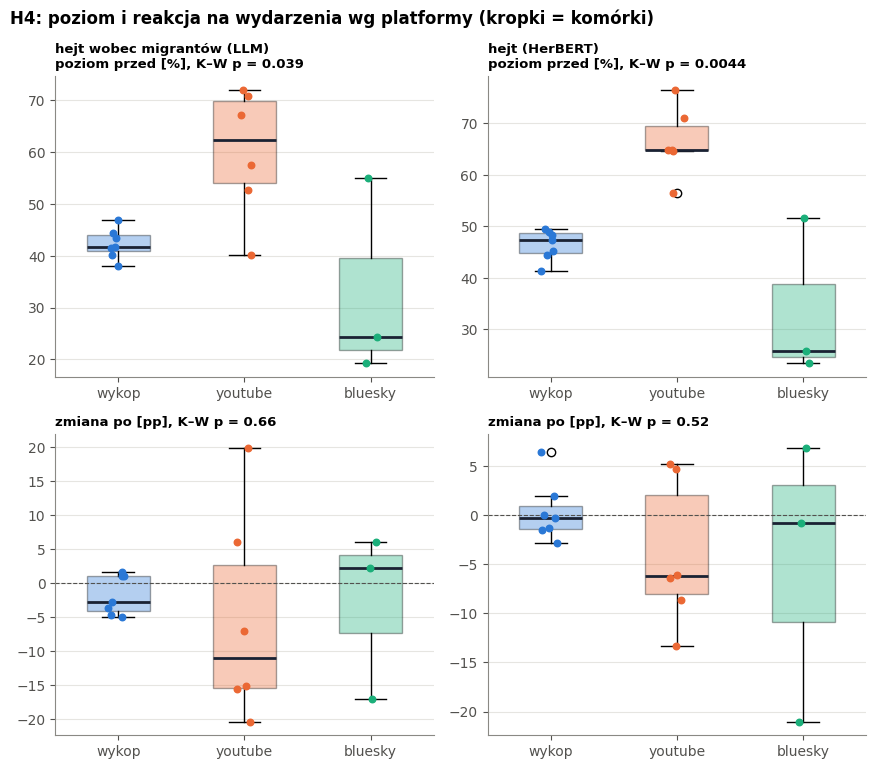

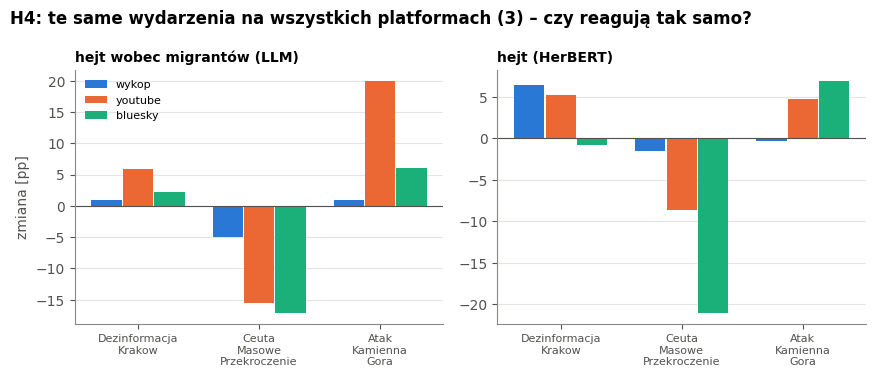

In [20]:
h4_rows = []
for meas in MEASURES:
    s = pp[pp["miara"] == meas]
    r_chg, post_chg = kw(s, "platform", "zmiana")
    r_lvl, post_lvl = kw(s.assign(poziom=s["przed"]), "platform", "poziom")
    wide = s[s["event"].isin(COMMON)].pivot_table(index="event", columns="platform", values="zmiana").dropna()
    fr_p = stats.friedmanchisquare(*[wide[c] for c in wide.columns]).pvalue if len(wide) >= 3 and wide.shape[1] == 3 else np.nan
    h4_rows.append({"miara": meas, "p reakcja (K–W)": r_chg["p"], "ε² reakcja": r_chg["ε²"], "p poziom (K–W)": r_lvl["p"],
                    "ε² poziom": r_lvl["ε²"], "p Friedman (wspólne wydarzenia)": fr_p, "wspólnych wydarzeń": len(wide),
                    **{f"mediana zmiany {p}": s[s["platform"] == p]["zmiana"].median() for p in PLATFORMS},
                    **{f"poziom przed {p} %": s[s["platform"] == p]["przed"].mean() for p in PLATFORMS}})
h4 = pd.DataFrame(h4_rows)
h4.to_csv(OUT / "h4.csv", index=False, encoding="utf-8-sig")
display(fmt_p(h4.set_index("miara").T, 3))

fig, axes = plt.subplots(2, len(MEASURES), figsize=(4.4 * len(MEASURES), 7.8))
for j, meas in enumerate(MEASURES):
    s = pp[pp["miara"] == meas]
    for i, (col, title) in enumerate([("przed", "poziom przed [%]"), ("zmiana", "zmiana po [pp]")]):
        ax = axes[i, j]
        vals = [s[s["platform"] == p][col].dropna() for p in PLATFORMS]
        pos = [k + 1 for k, v in enumerate(vals) if len(v)]
        bp = ax.boxplot([v for v in vals if len(v)], positions=pos, widths=0.5, patch_artist=True,
                        medianprops={"color": INK, "lw": 2})
        for patch, k in zip(bp["boxes"], pos):
            patch.set_facecolor(PLAT_COLORS[PLATFORMS[k - 1]]); patch.set_alpha(0.35)
        for k, v in enumerate(vals, 1):
            ax.scatter(np.full(len(v), k) + rng.uniform(-0.08, 0.08, len(v)), v, color=PLAT_COLORS[PLATFORMS[k - 1]], s=22, zorder=3)
        ax.set_xticks(range(1, 4), PLATFORMS)
        if col == "zmiana":
            ax.axhline(0, ls="--", color=INK2, lw=0.8)
        pv = h4.set_index("miara").loc[meas, "p reakcja (K–W)" if col == "zmiana" else "p poziom (K–W)"]
        ax.set_title(f"{MEASURE_NAMES[meas]}\n{title}, K–W p = {pv:.2g}" if i == 0 else f"{title}, K–W p = {pv:.2g}", fontsize=9.5)
fig.suptitle("H4: poziom i reakcja na wydarzenia wg platformy (kropki = komórki)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); savefig(fig, "6_h4_platformy"); plt.show()

# te same wydarzenia na 3 platformach
if COMMON:
    fig, axes = plt.subplots(1, len(MEASURES), figsize=(4.4 * len(MEASURES), 3.8), sharey=False)
    for ax, meas in zip(axes, MEASURES):
        s = pp[(pp["miara"] == meas) & pp["event"].isin(COMMON)]
        x = np.arange(len(COMMON))
        for k, p in enumerate(PLATFORMS):
            v = s[s["platform"] == p].set_index("event").reindex(COMMON)["zmiana"]
            ax.bar(x + (k - 1) * 0.26, v, 0.25, color=PLAT_COLORS[p], label=p)
        ax.axhline(0, color=INK2, lw=0.8)
        ax.set_xticks(x, [e.replace("_", "\n") for e in COMMON], fontsize=8)
        ax.set_title(MEASURE_NAMES[meas], fontsize=10)
    axes[0].set_ylabel("zmiana [pp]"); axes[0].legend(fontsize=8)
    fig.suptitle(f"H4: te same wydarzenia na wszystkich platformach ({len(COMMON)}) – czy reagują tak samo?", x=0.01, ha="left", fontweight="bold")
    plt.tight_layout(); savefig(fig, "6_h4_wspolne_wydarzenia"); plt.show()

## 9. Treść i autorzy hejtu (z analizy Oli)

Najciekawsze części `cross_platform_hate_analysis.ipynb` (sekcje 3–6), policzone tu na tych samych komórkach
co testy hipotez. Materiał: komentarze `hate_migrant = 1` (LLM), cały okres −7…+14, bez duplikatów z nakładających się
okien Wykopu.

- **9a. Słowa** – lematy (simplemma), bez stop-słów; słowa wyróżniające hejt vs komentarze o migracji bez hejtu:
  log-odds z priorytetem Dirichleta (Monroe i in. 2008), `z` > 2 ≈ wyraźnie częstsze w hejcie.
- **9b. Kogo obrażano** – słowa kluczowe grup docelowych (`TARGET_GROUPS` z notebooka Oli).
- **9c. Autorzy** – koncentracja hejtu (Gini, krzywa Lorenza); tylko Wykop i Bluesky (YouTube nie ma autorów).
- **9d. Polubienia** – czy hejt zbiera więcej polubień niż komentarze o migracji bez hejtu (model ujemny dwumianowy
  z kontrolą wydarzenia, błędy klastrowane po wątku).

In [21]:
import re
from collections import Counter
try:
    import simplemma
except ImportError:          # bez lematyzacji, gdyby pakietu nie było (requirements.txt go zawiera)
    simplemma = None
try:
    from wordcloud import WordCloud
    from matplotlib import font_manager
except ImportError:
    WordCloud = None

STOPWORDS_PL = set("""
a aby ach acz aczkolwiek aj albo ale ależ ani aż bardziej bardzo bez bo bowiem by byli bym bynajmniej być był była było były będzie będą
cali cała cały chce chcą ci cię ciebie co cokolwiek coraz coś czasami czasem czemu czy czyli często daleko dla dlaczego dlatego do dobrze
dokąd dość dużo dwa dwaj dwie dwoje dziś dzisiaj gdy gdyby gdyż gdzie gdziekolwiek gdzieś go i ich ile im inna inne inny innych iż ja ją
jak jakaś jakby jaki jakichś jakie jakiś jakiż jakkolwiek jako jakoś je jeden jedna jedno jednak jednakże jego jej jemu jest jestem jeszcze
jeśli jeżeli już ją każdy kiedy kilka kimś kto ktokolwiek ktoś która które którego której który których którym którzy ku lat lecz lub
ma mają mam mamy mało mi mimo między mną mnie mogą moi moim moja moje może możliwe można mój mu musi my na nad nam nami nas nasi nasz nasza
nasze naszego naszych natomiast natychmiast nawet nic nich nie niech niego niej niemu nigdy nim nimi niż no o obok od około on ona one oni
ono oraz oto owszem pan pana pani po pod podczas pomimo ponad ponieważ powinien powinna powinni powinno poza prawie przecież przed przede
przedtem przez przy roku również sam sama są się skąd sobie sobą sposób swoje ta tak taka taki takie także tam te tego tej temu ten teraz
też to tobą tobie toteż trzeba tu tutaj twoi twoim twoja twoje twym twój ty tych tylko tym u w wam wami was wasz wasza wasze we według
wiele wielu więc więcej wszyscy wszystkich wszystkie wszystkim wszystko wtedy wy właśnie z za zapewne zawsze ze zł znowu znów został żaden
żadna żadne żadnych że żeby tez juz sie jak ktory ktora ktore bylo byl beda bedzie moze takze zeby ze tylko wiec niz przez tego tym jeszcze
tych tej mnie mieć mają ma mial miał było będą bylo były jakis jakies cos nikt nikogo niczego wszystkiego swój swoją swojej swoich swoim
naszym tymi takich takiej takim tamtych coś ktoś kogoś czegoś bym byś byście byśmy będę będziesz będziemy jestes jesteś jesteśmy
http https www com html pdf amp quot xd xdd xddd lenny bo tam tu oni ich sa sā też dla gdzie potem teraz chyba raczej
link user email phone mieć móc chcieć wiedzieć mówić czas rok raz ten taki który swój wszystek inny jakiś cały sam też
""".split())

URL_RE = re.compile(r"https?://\S+|www\.\S+|@\w+|\[\w+\]")
TOKEN_RE = re.compile(r"[a-ząćęłńóśźż]{3,}")
_LEMMA = {}


def lemma(t):
    if t not in _LEMMA:
        _LEMMA[t] = (simplemma.lemmatize(t, lang="pl") if simplemma else t).lower()
    return _LEMMA[t]


STOP = STOPWORDS_PL | {lemma(w) for w in STOPWORDS_PL}


def tokens(text):
    toks = [lemma(t) for t in TOKEN_RE.findall(URL_RE.sub(" ", text.lower()))]
    return [t for t in toks if t not in STOP and len(t) >= 3]


def count_terms(texts):
    uni, bi = Counter(), Counter()
    for txt in texts:
        t = tokens(txt)
        uni.update(t)
        bi.update(f"{a} {b}" for a, b in zip(t, t[1:]))
    return uni, bi


def log_odds(c1, c2, prior, min_count=10):
    """Ważony log-odds ratio z informatywnym priorem Dirichleta (Monroe i in. 2008); z > 0 = częstsze w c1."""
    n1, n2, a0 = sum(c1.values()), sum(c2.values()), sum(prior.values())
    rows = []
    for w, y1 in c1.items():
        if y1 < min_count:
            continue
        a, y2 = prior[w], c2.get(w, 0)
        delta = np.log((y1 + a) / (n1 + a0 - y1 - a)) - np.log((y2 + a) / (n2 + a0 - y2 - a))
        rows.append((w, y1, y2, delta / np.sqrt(1 / (y1 + a) + 1 / (y2 + a))))
    return pd.DataFrame(rows, columns=["słowo", "n hejt", "n bez hejtu", "z"]).sort_values("z", ascending=False)

def log_odds(c1, c2, prior, min_count=10):
    """Ważony log-odds z informatywnym priorem Dirichleta (Monroe i in. 2008); z > 0 = częstsze w c1."""
    n1, n2, a0 = sum(c1.values()), sum(c2.values()), sum(prior.values())
    rows = []
    for w, y1 in c1.items():
        if y1 < min_count:
            continue
        a, y2 = prior[w], c2.get(w, 0)
        delta = np.log((y1 + a) / (n1 + a0 - y1 - a)) - np.log((y2 + a) / (n2 + a0 - y2 - a))
        rows.append((w, y1, y2, delta / np.sqrt(1 / (y1 + a) + 1 / (y2 + a))))
    return pd.DataFrame(rows, columns=["słowo", "n hejt", "n bez hejtu", "z"]).sort_values("z", ascending=False)


def barh(ax, labels, values, color, title, xlabel, notes=None):
    ax.barh(labels[::-1], values[::-1], color=color, height=0.65)
    if notes is not None:
        for yi, (v, n) in enumerate(zip(values[::-1], notes[::-1])):
            ax.text(v, yi, f" {n}", va="center", color=INK2, fontsize=7.5)
    ax.margins(x=0.25); ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
    ax.tick_params(axis="y", labelsize=8.5); ax.set_title(title, fontsize=11); ax.set_xlabel(xlabel)


uniq = df.drop_duplicates(["platform", "uid"])
hm = uniq[uniq["hate_migrant"]]
nh = uniq[uniq["migrant"] & ~uniq["hate_migrant"]]
print("komentarze z hejtem wobec migrantów:", hm.groupby("platform").size().reindex(PLATFORMS).to_dict())
print("komentarze o migracji bez hejtu:   ", nh.groupby("platform").size().reindex(PLATFORMS).to_dict())
terms = {}
for p in PLATFORMS:
    terms[(p, "hejt")] = count_terms(hm.loc[hm["platform"] == p, "text"])
    terms[(p, "bez")] = count_terms(nh.loc[nh["platform"] == p, "text"])
uni_h = sum((terms[(p, "hejt")][0] for p in PLATFORMS), Counter())
uni_n = sum((terms[(p, "bez")][0] for p in PLATFORMS), Counter())
bi_h = sum((terms[(p, "hejt")][1] for p in PLATFORMS), Counter())
bi_n = sum((terms[(p, "bez")][1] for p in PLATFORMS), Counter())

komentarze z hejtem wobec migrantów: {'wykop': 8996, 'youtube': 11581, 'bluesky': 420}
komentarze o migracji bez hejtu:    {'wykop': 13318, 'youtube': 10361, 'bluesky': 826}


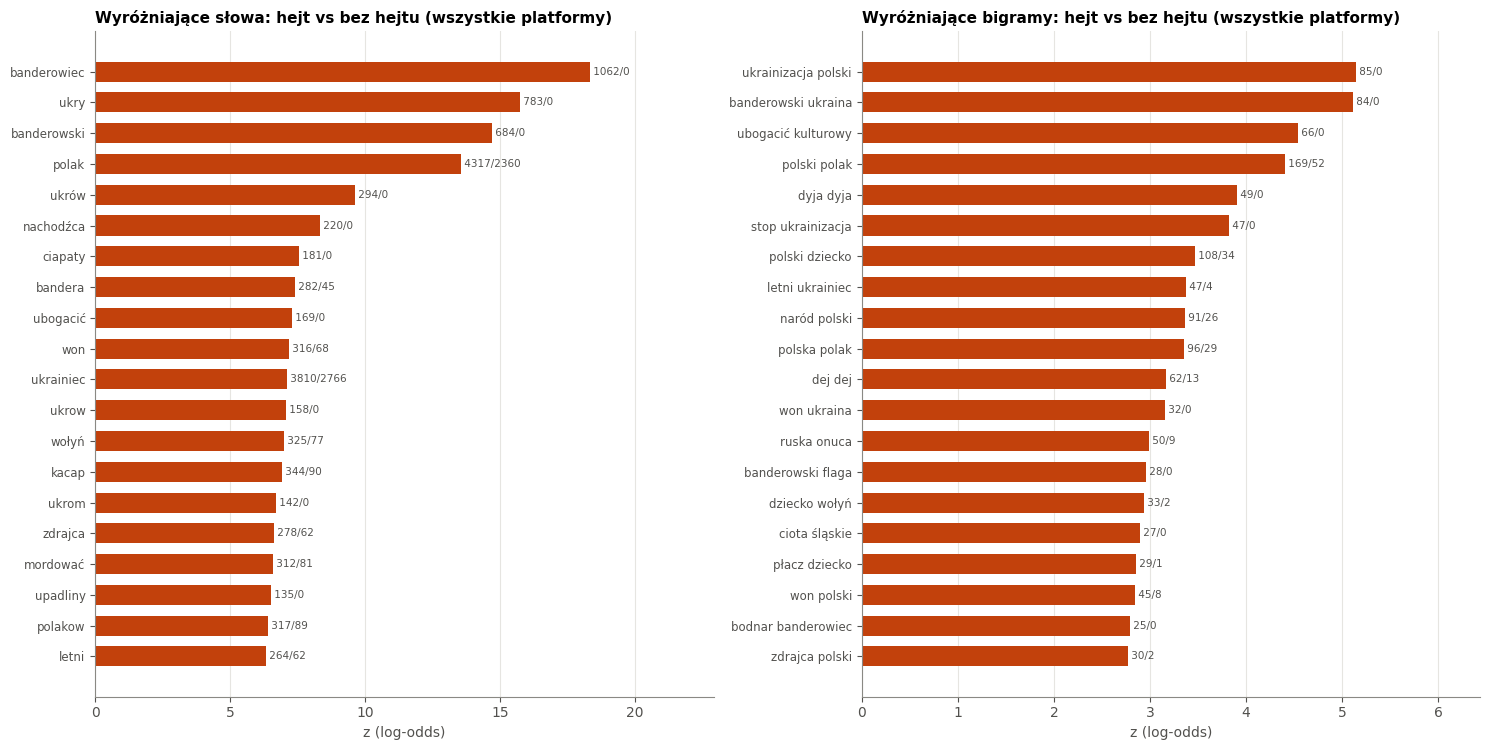

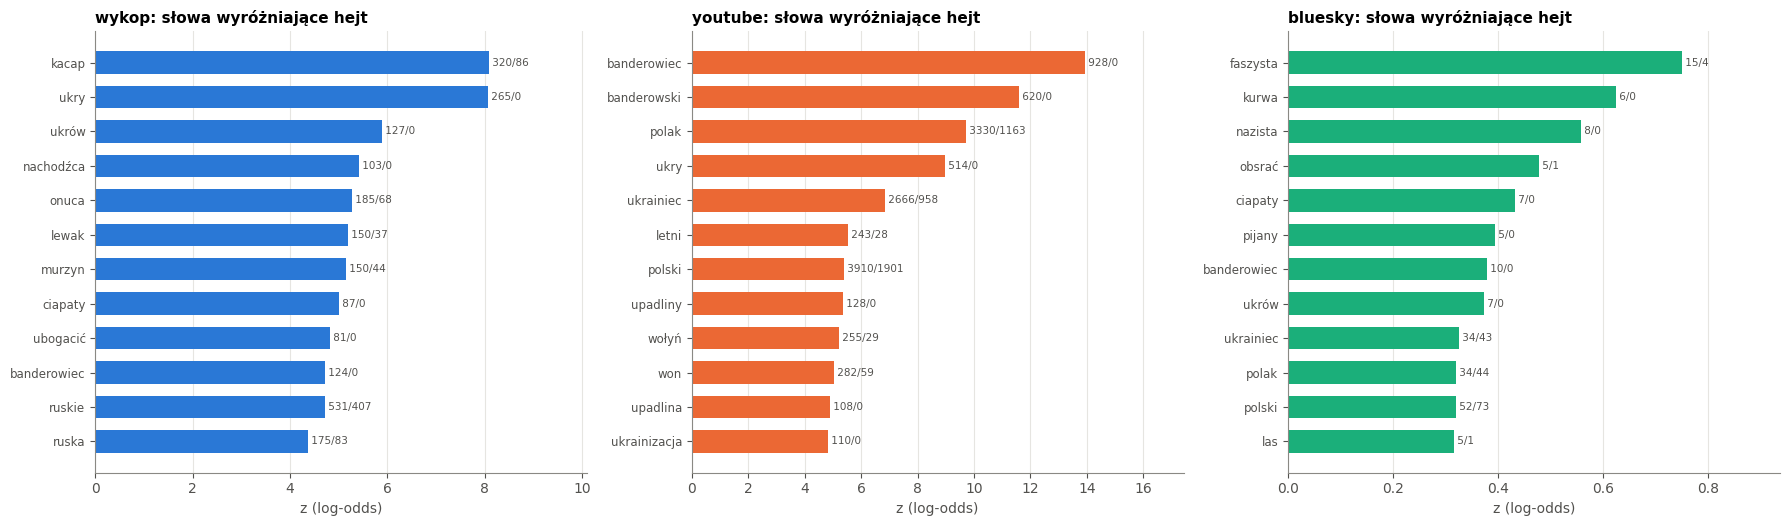

Liczby przy słupkach: wystąpienia w hejcie / w komentarzach o migracji bez hejtu.


In [22]:
# 9a. słowa i bigramy wyróżniające hejt (wszystkie platformy) + słowa wyróżniające per platforma
TOP_N = 20
fig, axes = plt.subplots(1, 2, figsize=(15, 0.3 * TOP_N + 1.6))
for ax, (c_h, c_n, kind, mc) in zip(axes, [(uni_h, uni_n, "słowa", 10), (bi_h, bi_n, "bigramy", 5)]):
    lo_ = log_odds(c_h, c_n, c_h + c_n, min_count=mc).head(TOP_N)
    barh(ax, lo_["słowo"].tolist(), lo_["z"].tolist(), "#c2410c", f"Wyróżniające {kind}: hejt vs bez hejtu (wszystkie platformy)",
         "z (log-odds)", notes=[f"{a}/{b}" for a, b in zip(lo_["n hejt"], lo_["n bez hejtu"])])
plt.tight_layout(); savefig(fig, "9a_slowa"); plt.show()

TOP_PL = 12
fig, axes = plt.subplots(1, 3, figsize=(18, 0.33 * TOP_PL + 1.4))
for ax, p in zip(axes, PLATFORMS):
    lo_ = log_odds(terms[(p, "hejt")][0], terms[(p, "bez")][0], uni_h + uni_n, min_count=5).head(TOP_PL)
    barh(ax, lo_["słowo"].tolist(), lo_["z"].tolist(), PLAT_COLORS[p], f"{p}: słowa wyróżniające hejt", "z (log-odds)",
         notes=[f"{a}/{b}" for a, b in zip(lo_["n hejt"], lo_["n bez hejtu"])])
plt.tight_layout(); savefig(fig, "9a_slowa_platformy"); plt.show()
print("Liczby przy słupkach: wystąpienia w hejcie / w komentarzach o migracji bez hejtu.")

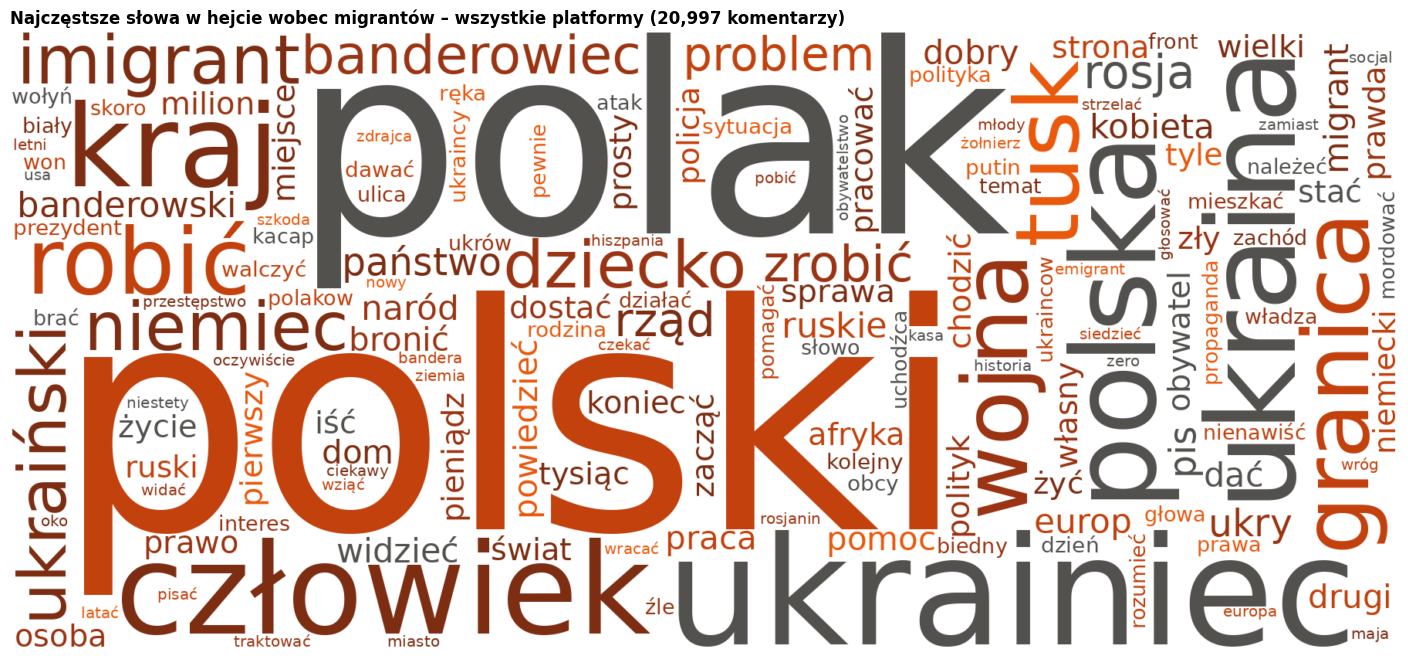

In [23]:
if WordCloud is not None:
    shades = ["#7c2d12", "#9a3412", "#c2410c", "#ea580c", "#52514e"]
    wc = WordCloud(width=1800, height=800, background_color="white", max_words=150, prefer_horizontal=0.95,
                   font_path=font_manager.findfont("DejaVu Sans"), random_state=0, margin=4,
                   color_func=lambda *a, random_state=None, **k: random_state.choice(shades)
                   ).generate_from_frequencies(dict(uni_h.most_common(400)))
    fig, ax = plt.subplots(figsize=(15, 6.7))
    ax.imshow(wc, interpolation="bilinear"); ax.axis("off")
    ax.set_title(f"Najczęstsze słowa w hejcie wobec migrantów – wszystkie platformy ({len(hm):,} komentarzy)")
    plt.tight_layout(); savefig(fig, "9a_chmura"); plt.show()
else:
    print("brak pakietu wordcloud – pomijam chmurę słów (pip install wordcloud)")

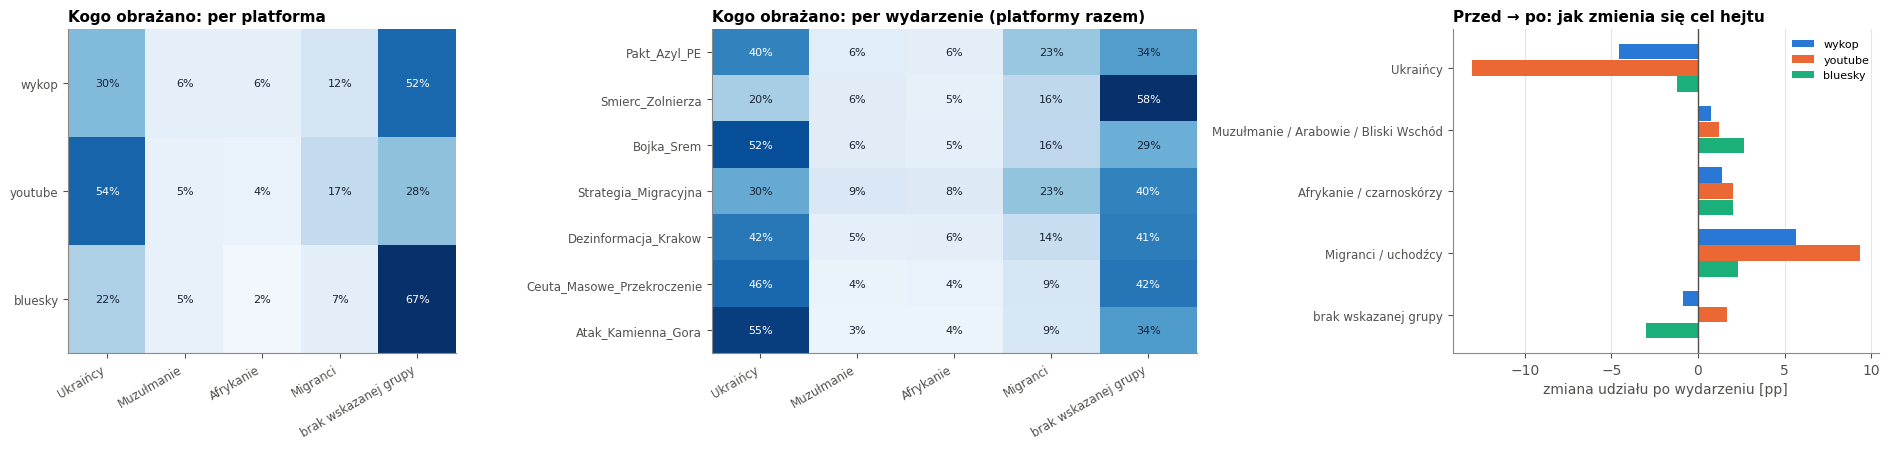

% komentarzy z hejtem wobec migrantów, które wspominają grupę (komentarz może trafić do kilku grup).


,Ukraińcy,Muzułmanie / Arabowie / Bliski Wschód,Afrykanie / czarnoskórzy,Migranci / uchodźcy (ogólnie),brak wskazanej grupy
platform,,,,,
wykop,29.8,6.1,6.0,11.9,52.4
youtube,53.6,4.9,4.5,17.1,27.7
bluesky,21.9,5.2,1.7,6.7,67.1


In [24]:
# 9b. kogo obrażano – grupy docelowe (słowa kluczowe z notebooka Oli)
TARGET_GROUPS = {
    "Ukraińcy": r"ukrai|ukraiń|\bukr|ukrop|bander|\bupa\b|upain|upowc|slava|sława|chachoł|chochoł",
    "Muzułmanie / Arabowie / Bliski Wschód": r"muzu?ł?m|muslim|islam|arab|allah|ciap|kozoj|talib|afga|syryj|syri|irak|turk|turc|pakist|czeczen|kebab|szariat|meczet",
    "Afrykanie / czarnoskórzy": r"murzyn|afryk|czarn|bambus|asfalt|nigeri|somal|erytre|małp|malp",
    "Migranci / uchodźcy (ogólnie)": r"migran|imigran|uchodź|uchodz|nachodź|nachodz|najeźdź|najezdz|relokac|azyl|ubogac|nielegal|przybysz|inwazj",
}
low = hm["text"].str.lower()
tg = pd.DataFrame({g: low.str.contains(rx, regex=True) for g, rx in TARGET_GROUPS.items()}, index=hm.index)
tg["brak wskazanej grupy"] = ~tg.any(axis=1)
tg[["platform", "event", "po"]] = hm[["platform", "event", "po"]]
cols_tg = list(TARGET_GROUPS) + ["brak wskazanej grupy"]

by_pl = 100 * tg.groupby("platform")[cols_tg].mean().reindex(PLATFORMS)
by_ev = 100 * tg.groupby("event")[cols_tg].mean().reindex(EVENT_ORDER)
chg = 100 * tg.groupby(["platform", "po"])[cols_tg].mean()

fig, axes = plt.subplots(1, 3, figsize=(19, 4.6), gridspec_kw={"width_ratios": [1, 1.25, 1.1]})
for ax, tab, title in [(axes[0], by_pl, "per platforma"), (axes[1], by_ev, "per wydarzenie (platformy razem)")]:
    vmax = np.nanmax(tab.values)
    ax.imshow(tab.values, cmap="Blues", aspect="auto", vmin=0, vmax=vmax)
    for (i, j), v in np.ndenumerate(tab.values):
        ax.text(j, i, f"{v:.0f}%", ha="center", va="center", fontsize=8, color="white" if v > 0.6 * vmax else INK)
    ax.set_xticks(range(len(cols_tg)), [c.split(" /")[0].split(" (")[0] for c in cols_tg], rotation=30, ha="right", fontsize=8.5)
    ax.set_yticks(range(len(tab)), tab.index, fontsize=8.5); ax.grid(False)
    ax.set_title(f"Kogo obrażano: {title}", fontsize=11)
ax = axes[2]
y = np.arange(len(cols_tg))
for k, p in enumerate(PLATFORMS):
    if (p, 0) in chg.index and (p, 1) in chg.index:
        d = chg.loc[(p, 1)] - chg.loc[(p, 0)]
        ax.barh(y + (k - 1) * 0.26, d.values, 0.25, color=PLAT_COLORS[p], label=p)
ax.axvline(0, color=INK2, lw=1); ax.set_yticks(y, [c.split(" (")[0] for c in cols_tg], fontsize=8.5); ax.invert_yaxis()
ax.grid(axis="x", visible=True); ax.grid(axis="y", visible=False); ax.legend(fontsize=8)
ax.set_xlabel("zmiana udziału po wydarzeniu [pp]"); ax.set_title("Przed → po: jak zmienia się cel hejtu", fontsize=11)
plt.tight_layout(); savefig(fig, "9b_grupy_docelowe"); plt.show()
print("% komentarzy z hejtem wobec migrantów, które wspominają grupę (komentarz może trafić do kilku grup).")
display(by_pl.round(1))

autorów  komentarzy  top 10% autorów [% treści]  Gini  śr. na autora  % autorów z ≥1 hejtem
platform co                                                                                                                          
wykop    wszystkie komentarze o migracji     6648       22314                       44.39  0.54           3.36                    NaN
         hejt wobec migrantów                4025        8996                       36.85  0.43           2.24                  60.54
bluesky  wszystkie komentarze o migracji      513        1246                       38.76  0.45           2.43                    NaN
         hejt wobec migrantów                 238         420                       35.00  0.36           1.76                  46.39

Wykop: 12% autorów hejtowało przy 3+ wydarzeniach i napisało 36% hejtu.


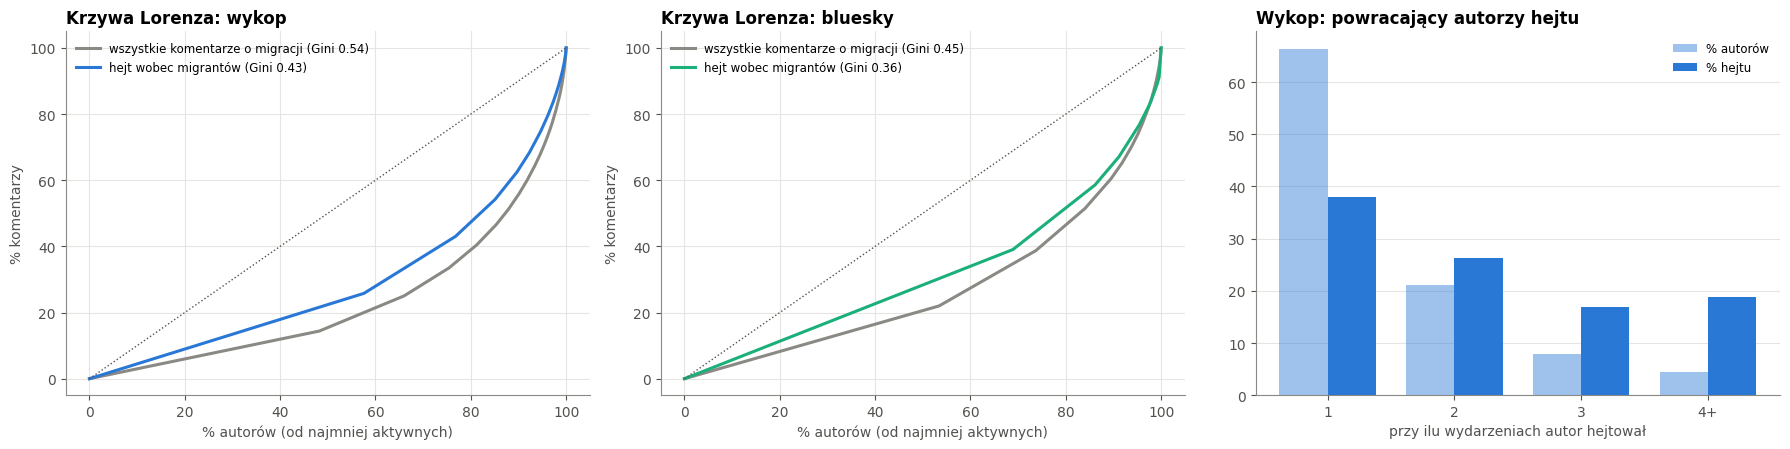

In [25]:
# 9c. koncentracja autorów hejtu
def gini(x):
    x = np.sort(np.asarray(x, float)); n = len(x)
    return np.nan if n == 0 or x.sum() == 0 else 2 * (np.arange(1, n + 1) * x).sum() / (n * x.sum()) - (n + 1) / n

def top_share(x, q):
    x = np.sort(np.asarray(x, float))[::-1]
    return 100 * x[:max(1, int(np.ceil(q * len(x))))].sum() / x.sum()

def lorenz(x):
    x = np.sort(np.asarray(x, float))
    return np.r_[0, np.arange(1, len(x) + 1) / len(x)], np.r_[0, np.cumsum(x) / x.sum()]

AUTH_PL = [p for p in ["wykop", "bluesky"] if uniq.loc[uniq["platform"] == p, "author_id"].notna().any()]
conc_rows, curves = [], {}
for p in AUTH_PL:
    d = uniq[(uniq["platform"] == p) & uniq["author_id"].notna()].copy()
    d["author"] = d["author_id"] if p == "wykop" else d["event"] + ":" + d["author_id"]   # Bluesky: pseudonimy per wydarzenie
    pa = d.groupby("author").agg(all=("comment_id", "size"), hate=("hate_migrant", "sum"))
    haters = pa.loc[pa["hate"] > 0, "hate"]
    curves[p] = {"wszystkie komentarze o migracji": pa["all"], "hejt wobec migrantów": haters}
    for name, x in curves[p].items():
        conc_rows.append({"platform": p, "co": name, "autorów": len(x), "komentarzy": int(x.sum()),
                          "top 10% autorów [% treści]": top_share(x, 0.10), "Gini": gini(x), "śr. na autora": x.mean()})
    conc_rows[-1]["% autorów z ≥1 hejtem"] = 100 * len(haters) / len(pa)
conc = pd.DataFrame(conc_rows).set_index(["platform", "co"])
display(conc.round(2))

fig, axes = plt.subplots(1, len(AUTH_PL) + 1, figsize=(6 * (len(AUTH_PL) + 1), 4.6), squeeze=False)
for ax, p in zip(axes[0], AUTH_PL):
    for name, x in curves[p].items():
        lx, ly = lorenz(x)
        ax.plot(lx * 100, ly * 100, color=MUTED if name.startswith("wszystkie") else PLAT_COLORS[p], lw=2.2,
                label=f"{name} (Gini {conc.loc[(p, name), 'Gini']:.2f})")
    ax.plot([0, 100], [0, 100], color=INK2, ls=":", lw=1)
    ax.set_xlabel("% autorów (od najmniej aktywnych)"); ax.set_ylabel("% komentarzy")
    ax.grid(axis="x", visible=True); ax.legend(loc="upper left", fontsize=8.5); ax.set_title(f"Krzywa Lorenza: {p}")
ax = axes[0][-1]
if "wykop" in AUTH_PL:
    d = df[(df["platform"] == "wykop") & df["hate_migrant"] & df["author_id"].notna()]
    rep = pd.DataFrame({"wydarzeń": d.groupby("author_id")["event"].nunique(),
                        "hejtów": d.drop_duplicates("comment_id").groupby("author_id").size()})
    tab = rep.groupby(rep["wydarzeń"].clip(upper=4)).agg(autorów=("hejtów", "size"), hejtów=("hejtów", "sum"))
    tab.index = [str(i) if i < 4 else "4+" for i in tab.index]
    x = np.arange(len(tab)); w = 0.38
    ax.bar(x - w / 2, 100 * tab["autorów"] / tab["autorów"].sum(), w, color=PLAT_COLORS["wykop"], alpha=0.45, label="% autorów")
    ax.bar(x + w / 2, 100 * tab["hejtów"] / tab["hejtów"].sum(), w, color=PLAT_COLORS["wykop"], label="% hejtu")
    ax.set_xticks(x, tab.index); ax.set_xlabel("przy ilu wydarzeniach autor hejtował")
    ax.legend(fontsize=8.5); ax.set_title("Wykop: powracający autorzy hejtu")
    core = rep["wydarzeń"] >= 3
    print(f"Wykop: {100 * core.mean():.0f}% autorów hejtowało przy 3+ wydarzeniach i napisało {100 * rep.loc[core, 'hejtów'].sum() / rep['hejtów'].sum():.0f}% hejtu.")
plt.tight_layout(); savefig(fig, "9c_autorzy"); plt.show()

,n hejt,n bez hejtu,mediana hejt,mediana bez,% ≥1 hejt,% ≥1 bez,P(hejt > bez),stosunek średnich (NB),lo,hi,p NB,p NB (Holm)
platform,,,,,,,,,,,,
wykop,8996,13318,1.0,1.0,60.938,57.449,0.519,1.107,0.992,1.234,0.0681,0.0681
youtube,11581,10361,0.0,1.0,48.890,50.208,0.477,0.523,0.445,0.615,3.74e-15,1.12e-14
bluesky,420,826,1.0,1.0,71.429,67.918,0.567,1.334,1.071,1.662,0.0101,0.0202


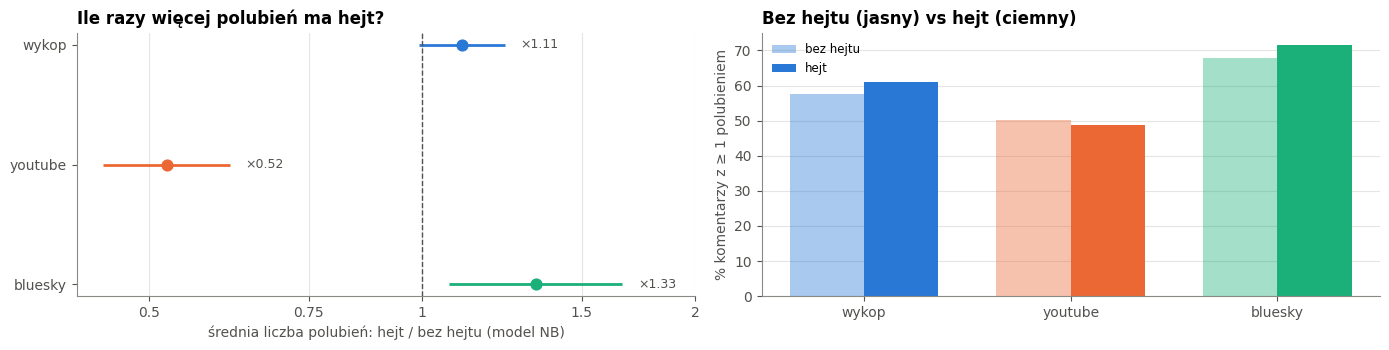

Na Wykopie `likes` to bilans plusów i minusów.


In [26]:
# 9d. czy hejt zbiera więcej polubień? (komentarze o migracji: z hejtem vs bez)
like_rows = []
for p in PLATFORMS:
    d = uniq[(uniq["platform"] == p) & uniq["migrant"]].dropna(subset=["likes"]).copy()
    if d.empty:
        continue
    h, n = d.loc[d["hate_migrant"], "likes"], d.loc[~d["hate_migrant"], "likes"]
    mw = stats.mannwhitneyu(h, n, alternative="two-sided")
    d["likes0"] = d["likes"].clip(lower=0).astype(int); d["hejt"] = d["hate_migrant"].astype(int)
    formula = "likes0 ~ hejt + C(event)" if d["event"].nunique() > 1 else "likes0 ~ hejt"
    try:
        m = smf.negativebinomial(formula, data=d).fit(disp=0, maxiter=300, cov_type="cluster",
                                                      cov_kwds={"groups": pd.factorize(d["thread"])[0]})
        b, s, pv = m.params["hejt"], m.bse["hejt"], m.pvalues["hejt"]
    except Exception as ex:
        print(p, "model NB nie zbiegł:", str(ex)[:80]); b = s = pv = np.nan
    like_rows.append({"platform": p, "n hejt": len(h), "n bez hejtu": len(n), "mediana hejt": h.median(), "mediana bez": n.median(),
                      "% ≥1 hejt": 100 * (h >= 1).mean(), "% ≥1 bez": 100 * (n >= 1).mean(),
                      "P(hejt > bez)": mw.statistic / (len(h) * len(n)),
                      "stosunek średnich (NB)": np.exp(b), "lo": np.exp(b - 1.96 * s), "hi": np.exp(b + 1.96 * s), "p NB": pv})
likes = pd.DataFrame(like_rows).set_index("platform")
likes["p NB (Holm)"] = multipletests(likes["p NB"].fillna(1), method="holm")[1]
display(fmt_p(likes, 3))

fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
ax = axes[0]; y = np.arange(len(likes))
for yi, (p, r) in zip(y, likes.iterrows()):
    ax.hlines(yi, r["lo"], r["hi"], color=PLAT_COLORS[p], lw=2)
    ax.scatter(r["stosunek średnich (NB)"], yi, s=60, color=PLAT_COLORS[p], zorder=3)
    ax.text(r["hi"] * 1.04, yi, f"×{r['stosunek średnich (NB)']:.2f}", va="center", fontsize=9, color=INK2)
ax.axvline(1, color=INK2, ls="--", lw=1); ax.set_xscale("log")
ax.set_xticks([0.5, 0.75, 1, 1.5, 2], ["0.5", "0.75", "1", "1.5", "2"]); ax.minorticks_off()
ax.set_yticks(y, likes.index); ax.invert_yaxis(); ax.grid(axis="x", visible=True); ax.grid(axis="y", visible=False)
ax.set_xlabel("średnia liczba polubień: hejt / bez hejtu (model NB)"); ax.set_title("Ile razy więcej polubień ma hejt?")
ax = axes[1]; w = 0.36
ax.bar(y - w / 2, likes["% ≥1 bez"], w, color=[PLAT_COLORS[p] for p in likes.index], alpha=0.4, label="bez hejtu")
ax.bar(y + w / 2, likes["% ≥1 hejt"], w, color=[PLAT_COLORS[p] for p in likes.index], label="hejt")
ax.set_xticks(y, likes.index); ax.set_ylabel("% komentarzy z ≥ 1 polubieniem"); ax.legend(fontsize=8.5)
ax.set_title("Bez hejtu (jasny) vs hejt (ciemny)")
plt.tight_layout(); savefig(fig, "9d_polubienia"); plt.show()
print("Na Wykopie `likes` to bilans plusów i minusów.")

## 10. Podsumowanie hipotez

Werdykt liczony automatycznie z testów z README (α = 0,05). Kolorem: zielony = potwierdzona, żółty = częściowo, szary = brak dowodów.

werdykt                                                                                   uzasadnienie
hipoteza miara                                                                                                                                  
H1       hejt wobec migrantów (LLM)     częściowo  brak efektu łącznego (Wilcoxon p=0.23, OR meta 0.83); istotne zmiany w 3/16 komórek (1/2 ↑/↓)
         hejt (HerBERT)              brak dowodów                                                        Wilcoxon p=0.35; brak istotnych komórek
H2       hejt wobec migrantów (LLM)  brak dowodów                             K–W p=0.067, ε²=0.35; największa mediana: dezinformacja (+2.21 pp)
         hejt (HerBERT)              brak dowodów                              K–W p=0.12, ε²=0.24; największa mediana: dezinformacja (+5.24 pp)
H3       hejt wobec migrantów (LLM)  brak dowodów                                Friedman p=0.17; średnio 0–3: -6.01, 4–7: -6.90, 8–14: -2.67 pp
         hejt (HerBERT)              brak dowodów                                Friedman p=0.57; średnio 0–3: -2.09, 4–7: -4.45, 8–14: -2.20 pp
H4       hejt wobec migrantów (LLM)     częściowo                                                         reakcja K–W p=0.66; poziom K–W p=0.039
         hejt (HerBERT)                 częściowo                                                        reakcja K–W p=0.52; poziom K–W p=0.0044

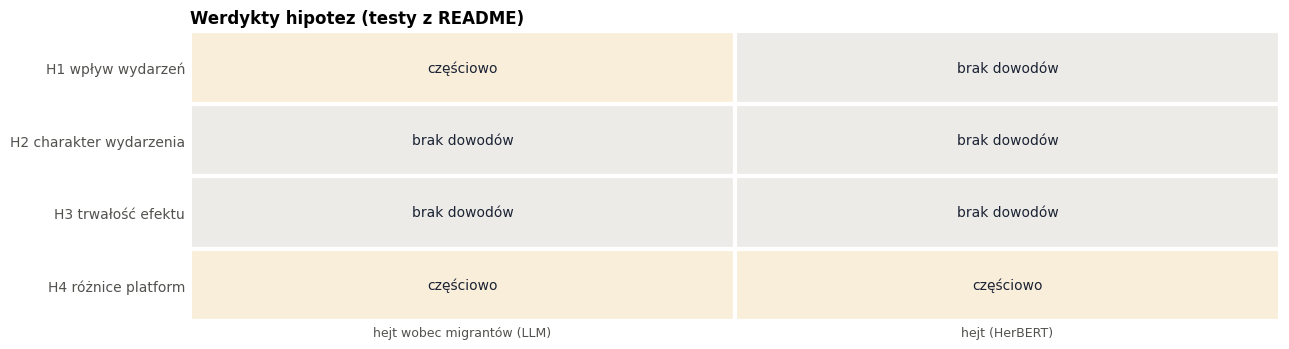

In [27]:
def verdict(meas):
    out = {}
    a = h1[(h1["miara"] == meas) & (h1["zakres"] == "wszystkie")].iloc[0]
    sig = eff[(eff["miara"] == meas) & (eff["kierunek"] != "–")]
    if a["p Wilcoxon"] < ALPHA or (pd.notna(a["p meta"]) and a["p meta"] < ALPHA):
        out["H1"] = ("potwierdzona", f"Wilcoxon p={a['p Wilcoxon']:.2g}, r={a['r']:.2f}; OR meta {a['OR meta']:.2f}")
    elif len(sig):
        out["H1"] = ("częściowo", f"brak efektu łącznego (Wilcoxon p={a['p Wilcoxon']:.2g}, OR meta {a['OR meta']:.2f}); "
                                   f"istotne zmiany w {len(sig)}/{int(a['komórek'])} komórek ({a['istotnie ↑/↓']} ↑/↓)")
    else:
        out["H1"] = ("brak dowodów", f"Wilcoxon p={a['p Wilcoxon']:.2g}; brak istotnych komórek")
    b = h2.set_index("miara").loc[meas]
    med = {t: b.get(f"mediana {t}") for t in TYPE_ORDER}
    top = max((t for t in med if pd.notna(med[t])), key=lambda t: med[t])
    out["H2"] = ("potwierdzona" if b["p"] < ALPHA else "brak dowodów",
                 f"K–W p={b['p']:.2g}, ε²={b['ε²']:.2f}; największa mediana: {top} ({med[top]:+.2f} pp)")
    c = h3[(h3["miara"] == meas) & (h3["zakres"] == "wszystkie")]
    if len(c):
        c = c.iloc[0]
        ms = [c[f"{w}: średnio pp"] for w in WN]
        decay = ms[0] == max(ms, key=abs) and abs(ms[-1]) < abs(ms[0])
        out["H3"] = ("potwierdzona" if (c["p Friedman"] < ALPHA and decay) else ("częściowo" if decay else "brak dowodów"),
                     f"Friedman p={c['p Friedman']:.2g}; średnio " + ", ".join(f"{w.replace('dni ', '')}: {m:+.2f}" for w, m in zip(WN, ms)) + " pp")
    d = h4.set_index("miara").loc[meas]
    react, lvl = d["p reakcja (K–W)"], d["p poziom (K–W)"]
    out["H4"] = ("potwierdzona" if react < ALPHA else ("częściowo" if lvl < ALPHA else "brak dowodów"),
                 f"reakcja K–W p={react:.2g}; poziom K–W p={lvl:.2g}")
    return out


V = {m: verdict(m) for m in MEASURES}
summary = pd.DataFrame([{"hipoteza": h, "miara": MEASURE_NAMES[m], "werdykt": V[m][h][0], "uzasadnienie": V[m][h][1]}
                        for h in ["H1", "H2", "H3", "H4"] for m in MEASURES if h in V[m]])
summary.to_csv(OUT / "podsumowanie_hipotez.csv", index=False, encoding="utf-8-sig")
pd.set_option("display.max_colwidth", 300)
display(summary.set_index(["hipoteza", "miara"]))

COLV = {"potwierdzona": "#cfe8d2", "częściowo": "#f9eeda", "brak dowodów": "#ecebe7"}
fig, ax = plt.subplots(figsize=(13, 3.6))
hs = ["H1", "H2", "H3", "H4"]
for i, h in enumerate(hs):
    for j, m in enumerate(MEASURES):
        v = V[m].get(h, ("–", ""))[0]
        ax.add_patch(plt.Rectangle((j, i), 1, 1, color=COLV.get(v, "white"), ec="white", lw=3))
        ax.text(j + 0.5, i + 0.5, v, ha="center", va="center", fontsize=10, color=INK)
ax.set_xlim(0, len(MEASURES)); ax.set_ylim(len(hs), 0)
ax.set_xticks(np.arange(len(MEASURES)) + 0.5, [MEASURE_NAMES[m] for m in MEASURES], fontsize=9)
ax.set_yticks(np.arange(len(hs)) + 0.5, ["H1 wpływ wydarzeń", "H2 charakter wydarzenia", "H3 trwałość efektu", "H4 różnice platform"])
ax.grid(False); ax.spines[:].set_visible(False); ax.tick_params(length=0)
ax.set_title("Werdykty hipotez (testy z README)")
plt.tight_layout(); savefig(fig, "7_werdykty"); plt.show()

In [28]:
# kluczowe liczby do raportu (generowane automatycznie)
m = eff[eff["miara"] == MAIN]
lines = [f"Dane: {len(CELLS)} komórek wydarzenie × platforma ({', '.join(f'{p}: {sum(c.startswith(p) for c in CELLS)}' for p in PLATFORMS)}), "
         f"{len(df):,} komentarzy w oknie {WINDOW[0]}…+{WINDOW[1]} dni."]
for meas in MEASURES:
    a = h1[(h1["miara"] == meas) & (h1["zakres"] == "wszystkie")].iloc[0]
    lines.append(f"- {MEASURE_NAMES[meas]}: wzrost w {a['wzrost w']} komórek, istotnie ↑/↓ {a['istotnie ↑/↓']}; "
                 f"łączny OR {a['OR meta']:.2f} [{a['OR lo']:.2f}; {a['OR hi']:.2f}], p = {a['p meta']:.2g}; Wilcoxon p = {a['p Wilcoxon']:.2g}")
top = m.reindex(m["zmiana pp"].abs().sort_values(ascending=False).index).head(3)
lines.append("Największe zmiany (miara główna): " + "; ".join("{} {:+.1f} pp ({})".format(r["cell"], r["zmiana pp"], r["kierunek"]) for _, r in top.iterrows()))
print("\n".join(lines))
(OUT / "kluczowe_liczby.txt").write_text("\n".join(lines) + "\n", encoding="utf-8")

Dane: 16 komórek wydarzenie × platforma (wykop: 7, youtube: 6, bluesky: 3), 46,545 komentarzy w oknie -7…+14 dni.
- hejt wobec migrantów (LLM): wzrost w 7/16 komórek, istotnie ↑/↓ 1/2; łączny OR 0.83 [0.67; 1.04], p = 0.096; Wilcoxon p = 0.23
- hejt (HerBERT): wzrost w 6/16 komórek, istotnie ↑/↓ 0/0; łączny OR 0.90 [0.77; 1.05], p = 0.15; Wilcoxon p = 0.35
Największe zmiany (miara główna): youtube:Atak_Kamienna_Gora +25.5 pp (↑); youtube:Pakt_Azyl_PE -23.8 pp (↓); youtube:Ceuta_Masowe_Przekroczenie -19.6 pp (–)


517

## 11. Wnioski

> Liczby pochodzą z komórek powyżej: 16 komórek (Wykop 7, YouTube 6, Bluesky 3), **46,5 tys. komentarzy o migracji**
> (z `labeled/`) w oknie −7…+14. Obie miary – LLM i HerBERT – liczone na tych samych komentarzach.

### Odpowiedź na pytanie badawcze

Wydarzenia związane z migracją **nie zmieniają systematycznie** tego, jak wroga jest dyskusja o migracji. Udział hejtu wobec
migrantów wśród komentarzy o migracji wzrósł w 7 z 16 komórek; łączny efekt jest bliski zera, raczej ujemny
(OR 0,83 [0,67; 1,04], p = 0,10; Wilcoxon p = 0,23). Istotne są tylko **3 komórki, wszystkie na YouTube**: wzrost po ataku
w Kamiennej Górze (36% → 62%) oraz spadki po Pakcie o migracji w PE (69% → 45%) i po strategii migracyjnej (59% → 40%).
Niezależny tor – **HerBERT** (hejt ogólny na tych samych komentarzach) – nie ma żadnej istotnej komórki (OR 0,90, p = 0,15).
Wydarzenia zmieniają raczej **ile** mówi się o migracji (komentarzy o migracji na dzień jest po wydarzeniach średnio ok. 1,3 raza
więcej – opisowo, na YouTube zawyżone sposobem zbierania filmów) niż **jak wrogo**.

### Hipotezy

| | werdykt | najważniejsze liczby |
|---|---|---|
| **H1** wpływ wydarzeń | **częściowo** – pojedyncze wydarzenia (YouTube), brak efektu ogólnego | LLM: istotnie ↑ 1, ↓ 2 z 16; OR 0,83, p = 0,10; HerBERT: 0 istotnych, OR 0,90 |
| **H2** charakter wydarzenia | **brak dowodów** (trend opisowy) | K–W p = 0,067 (HerBERT 0,12); mediana zmiany: dezinformacja +2,2 pp, kryminalne −0,9, polityczne −9,4, kryzys graniczny −15,6 pp |
| **H3** trwałość efektu | **brak dowodów** | brak szczytu w dniach 0–3: −6,0 / −6,9 / −2,7 pp w oknach 0–3 / 4–7 / 8–14 (Friedman p = 0,17; HerBERT 0,57) |
| **H4** różnice platform | **częściowo** – różny **poziom**, ta sama **reakcja** | poziom: YouTube 60% > Wykop 42% > Bluesky 33% (K–W p = 0,04; HerBERT 66% > 46% > 34%, p = 0,004); reakcja: p = 0,66 (HerBERT 0,52) |

- **H2:** opisowo kryzys graniczny (Ceuta) i wydarzenia polityczne mają spadek udziału hejtu, dezinformacja – lekki wzrost.
  Przy 7 wydarzeniach (po jednym w dwóch typach) to trend, nie wynik istotny.
- **H4:** teraz wszystkie poziomy liczymy na komentarzach o migracji, więc są porównywalne między platformami:
  YouTube jest najbardziej wrogi, Bluesky najmniej; platformy reagują jednak na wydarzenia podobnie.

### Jakość etykiet (część 2)

HerBERT jest najlepszym klasyfikatorem hejtu (F1 0,78 na 600 komentarzach gold; Polbert 0,64, RoBERTa-BAN-PL 0,54,
sam słownik 0,26). LLM oceniamy tylko na komentarzach gold z `labeled/` (349 – o migracji), tak jak w analizie:
`hate` F1 0,74 (HerBERT na tych samych komentarzach 0,79), `hate_migrant` F1 0,59. `hate_migrant` jest więc najmniej
pewną etykietą – dlatego ważne jest, że HerBERT daje zgodne wnioski.

### Treść i autorzy hejtu (część 9, na bazie analizy Oli)

- **Słowa:** hejt wobec migrantów to przede wszystkim słownictwo **antyukraińskie** – najbardziej wyróżniające słowa to
  „banderowiec”, „ukry”, „banderowski”, „ukrów”, a bigramy „ukrainizacja Polski”, „banderowska Ukraina”, „stop ukrainizacja”;
  dalej „nachodźca”, „ciapaty”, „ubogacić (kulturowo)”, „Wołyń”, „won”.
- **Kogo obrażano:** Ukraińców wspomina 54% hejtu wobec migrantów na YouTube, 30% na Wykopie i 22% na Bluesky; inne grupy
  (muzułmanie, Afrykanie) po kilka procent. Po wydarzeniach udział hejtu wobec Ukraińców **spada**, a wobec
  **migrantów / uchodźców ogólnie rośnie** – wydarzenia przesuwają cel hejtu na migrantów, o których akurat się mówi.
- **Autorzy:** hejt wobec migrantów jest **rozproszony** – mniej skoncentrowany niż całe pisanie o migracji
  (Gini: Wykop 0,43 vs 0,54, Bluesky 0,36 vs 0,45); 61% autorów piszących o migracji na Wykopie napisało choć jeden
  taki komentarz (Bluesky 46%). Jest jednak rdzeń: 12% autorów Wykopu hejtowało przy 3+ wydarzeniach i napisało 36% hejtu.
- **Polubienia:** na Bluesky hejt zbiera więcej polubień niż komentarze o migracji bez hejtu (×1,33, istotne), na Wykopie
  nieco więcej (×1,11, p = 0,07), a na YouTube **dwa razy mniej** (×0,52). Nie ma uniwersalnego „nagradzania hejtu”.

### Ograniczenia

- analizujemy tylko komentarze o migracji wybrane przez zespół (`labeled/`: słownik obelg albo filtr słów o migracji + LLM);
  hejt wobec migrantów bez żadnego słowa o migracji w komentarzu, wpisie i komentarzu nadrzędnym nie jest analizowany –
  tak samo przed i po wydarzeniu;
- 7 wydarzeń (dezinformacja i kryzys graniczny – po jednym), na Bluesky 3 wydarzenia (wcześniejsze mają za mało komentarzy);
- YouTube: krótki okres „przed” (filmy zbierane wokół wydarzenia), YouTube / Śmierć żołnierza wykluczone;
- gold standard oznaczony przez modele językowe z rozstrzyganiem sporów, a etykieta `hate_migrant` pochodzi tylko z LLM;
- na Wykopie liczba komentarzy o migracji dla części wydarzeń różni się od notebooka Oli (inna wersja pliku z etykietami
  i to, że obelgi ze słownika liczymy jako komentarze o migracji – jak na YouTube i Bluesky).

**Analiza uzupełniająca:** hejt ogólny (HerBERT) na wszystkich 15 wydarzeniach i w oknie ±28 dni –
`6_wyniki_koncowe/uzupelniajace_herbert_15_wydarzen.ipynb` (dla 8 wydarzeń bez `labeled/` jedyną selekcją jest filtr
tematyczny, więc tam mianownikiem są komentarze z filtra; ten sam wniosek: brak systematycznego wzrostu).